In [1]:
import jpype
import os
from jpype import JClass

jar_path = os.path.abspath("infodynamics.jar")
jpype.startJVM(classpath=[jar_path])

TECalcClass = jpype.JPackage("infodynamics.measures.continuous.kraskov").TransferEntropyCalculatorKraskov
teCalc = TECalcClass()

from jpype import JPackage
CTEClass = JPackage("infodynamics.measures.continuous.kraskov").ConditionalTransferEntropyCalculatorKraskov
cteCalc = CTEClass()

MIClass = jpype.JPackage("infodynamics.measures.continuous.kraskov").MutualInfoCalculatorMultiVariateKraskov1
miCalc = MIClass()

In [2]:
import sys
sys.path.insert(0,r"C:\Users\alons\Master Ciencia de Datos/TFM/Git Hub/notebooks/IDTxl-master/IDTxl-master")

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from typing import Tuple
from tqdm import tqdm
import pandas as pd

import math
np.math = math
from idtxl.multivariate_te import MultivariateTE
from idtxl.data import Data
from idtxl.visualise_graph import plot_network

from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression

from scipy.stats import gaussian_kde, ks_2samp
from scipy.signal import welch

In [4]:
def find_optimal_tau_TE_JIDT(V1, V2, n_vecinos, max_steps=600, contexto_k=5, contexto_l=5, contexto_c=50, factor_bool=True, plot=False, inverse=False, conditional=False, padres_source=None):
    """
    Calcula la Transfer Entropy (TE) para distintos valores de tau_source con el código de JIDT.
    Si inverse=True:
        calcula también V2 -> V1.
    Si conditional=True:
        calcula también la CTE V1 -> V2 | V2
    Retorna:
        tau_values, te_direct, optimal_tau

    """
    tau_values = np.arange(1, max_steps + 1)
    te_results = []

    if inverse:
        te_inverse_results = []
        
    if conditional:
        cte_results = []
    
    factor = 5   

    if factor_bool:
        V1 = V1[::factor]
        V2 = V2[::factor]

    hist = max(contexto_k, contexto_l, contexto_c)
    V1 = V1[hist:]
    V2 = V2[hist:]

        
        # --- TE Directa (V1 -> V2) ---
    teCalc = TECalcClass()
    teCalc.setProperty("k", str(n_vecinos))
    teCalc.setProperty("k_HISTORY", str(contexto_k))
    teCalc.setProperty("l_HISTORY", str(contexto_l))
    

    for tau in tqdm(tau_values, desc="Análisis de Tau", unit="tau"):
        
        teCalc.setProperty("DELAY", str(tau))
        teCalc.initialise()
        teCalc.setObservations(V1.astype(np.float64), V2.astype(np.float64))
        te = teCalc.computeAverageLocalOfObservations()
        te_results.append(te)

         # --- TE Inversa (V2 -> V1) ---
    if inverse:
    
            teCalc_inv = TECalcClass()
            teCalc_inv.setProperty("k", str(n_vecinos))
            teCalc_inv.setProperty("k_HISTORY", str(contexto_k))
            teCalc_inv.setProperty("l_HISTORY", str(contexto_l))
    
            for tau in tqdm(tau_values, desc="TE V2 → V1", unit="tau"):
                teCalc_inv.setProperty("DELAY", str(tau))
                teCalc_inv.initialise()
                teCalc_inv.setObservations(V2.astype(np.float64),V1.astype(np.float64))
                te_inv = teCalc_inv.computeAverageLocalOfObservations()
                te_inverse_results.append(te_inv)
                

        # --- CTE (V1 -> V2 | V2) ---
    if conditional:
        cteCalc = CTEClass() 
        cteCalc.setProperty("k", str(n_vecinos))
        cteCalc.setProperty("k_HISTORY", str(contexto_k))
        cteCalc.setProperty("l_HISTORY", str(contexto_l))
        cteCalc.setProperty("c_HISTORY", str(contexto_c))
    
        for tau in tqdm(tau_values, desc="CTE V1 → V2 | V2", unit="tau"):
            cteCalc.setProperty("DELAY", str(tau))
            cteCalc.initialise()
            cteCalc.setObservations(V1.astype(np.float64), V2.astype(np.float64), V2.astype(np.float64))
            cte_val = cteCalc.computeAverageLocalOfObservations()
            cte_results.append(cte_val)


    te_results = np.array(te_results)
    if inverse:
        te_inverse_results = np.array(te_inverse_results)
    if conditional:
        cte_results = np.array(cte_results)

    optimal_idx = np.argmax(te_results)
    optimal_tau = tau_values[optimal_idx]
    
    if factor_bool:
        optimal_tau = optimal_tau * factor
        tau_values = tau_values * factor

    # Gráfica
    if plot:

        plt.figure(figsize=(10, 6))
        plt.plot(tau_values, te_results, lw=2, label="Transfer Entropy (Direct)")
        if padres_source is not None:
            if np.isscalar(padres_source):
                padres_source = [padres_source]
            for i, delay in enumerate(padres_source):
                if delay in tau_values:
                    idx = np.where(tau_values == delay)[0][0]
                    plt.scatter(tau_values[idx], te_results[idx], marker="*", s=250, zorder=5, label="Padre seleccionado" if i == 0 else None)
        if inverse:
            plt.plot(tau_values, te_inverse_results, color="gray", alpha=0.45, lw=1.8, linestyle="--", label="TE V2 → V1")
        if conditional:
            plt.plot(tau_values, cte_results, color="red", alpha=0.35, lw=1.8, linestyle="--", label="CTE V1 → V2 | V2")
        plt.axvline(tau_values[optimal_idx], linestyle="--", alpha=0.7)
        plt.xlabel("Delay")
        plt.ylabel("Transfer Entropy")
        plt.title(f"TE (JIDT-Kraskov) vs Delay "f"(k={n_vecinos})")
        plt.grid(True)
        plt.legend()
        plt.show()


    return tau_values, te_results, optimal_tau

![Circuito del pez eléctrico](circuito_pez_electrico.png)

## ACCELERATIONS

In [5]:
data1 = pd.read_csv("SGA_acc.txt", sep=r"\s+", header=None)
accelerations = data1.iloc[:, -4:].copy()
accelerations.columns = ["VPd", "DP", "PCN", "CN"]

accelerations.head()

,VPd,DP,PCN,CN
0,-65.0912,-63.635,-64.4749,-64.8126
1,-65.0843,-63.635,-64.4671,-64.8124
2,-65.0774,-63.635,-64.4594,-64.8122
3,-65.0704,-63.635,-64.4516,-64.8120
4,-65.0635,-63.635,-64.4438,-64.8118


In [6]:
DP = accelerations["DP"].to_numpy()
CN = accelerations["CN"].to_numpy()
VPd = accelerations["VPd"].to_numpy()
PCN = accelerations["PCN"].to_numpy()

Análisis de Tau: 100%|██████████| 450/450 [07:32<00:00,  1.01s/tau]


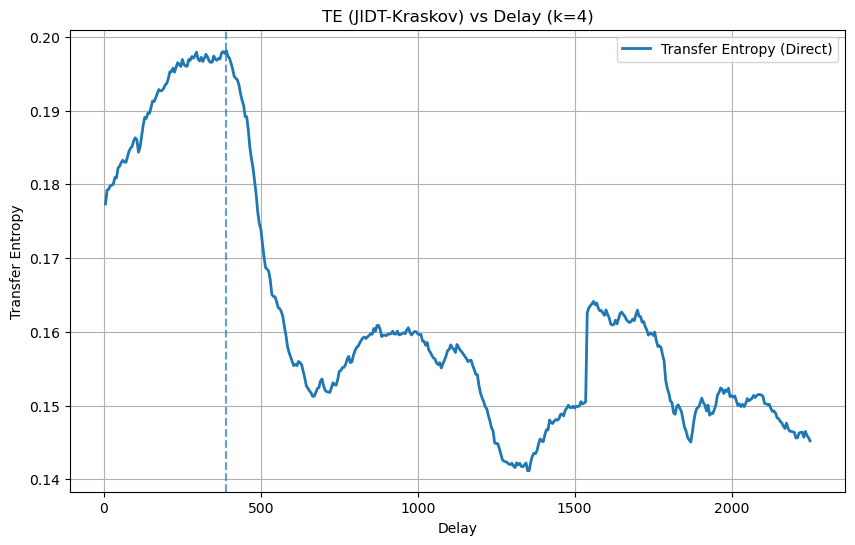

El delay óptimo para k=4 es: 390.000 ms


In [24]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(DP, CN, n_vecinos=4, max_steps=450, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [06:14<00:00,  3.75s/tau]


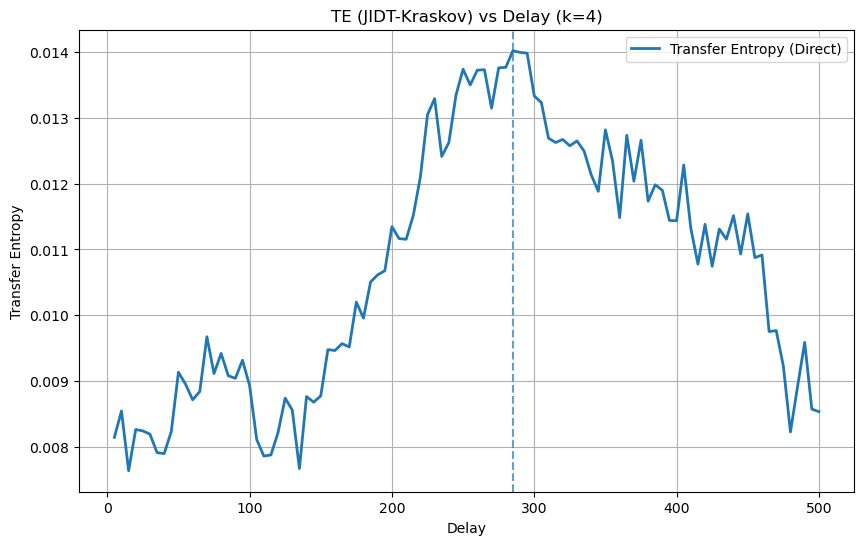

El delay óptimo para k=4 es: 285.000 ms


In [27]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(CN, DP, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [06:27<00:00,  3.88s/tau]


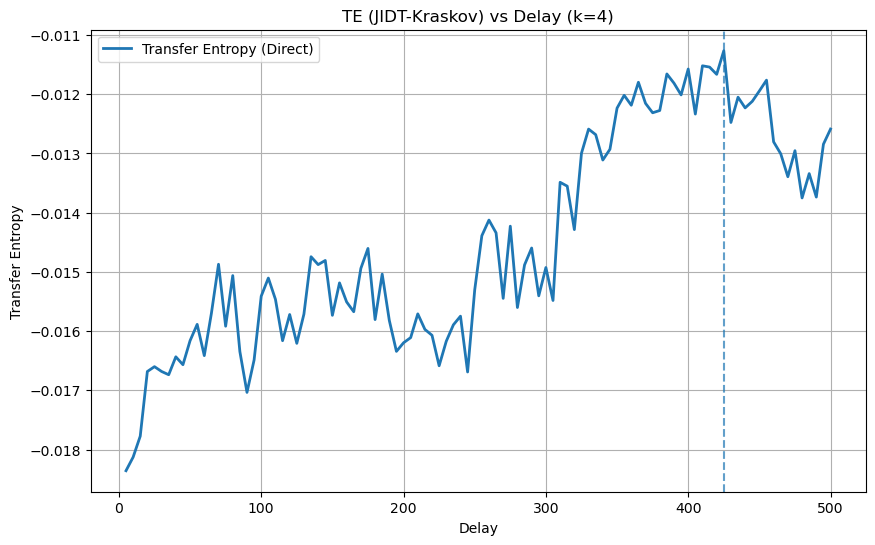

El delay óptimo para k=4 es: 425.000 ms


In [28]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(VPd, DP, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [01:33<00:00,  1.07tau/s]


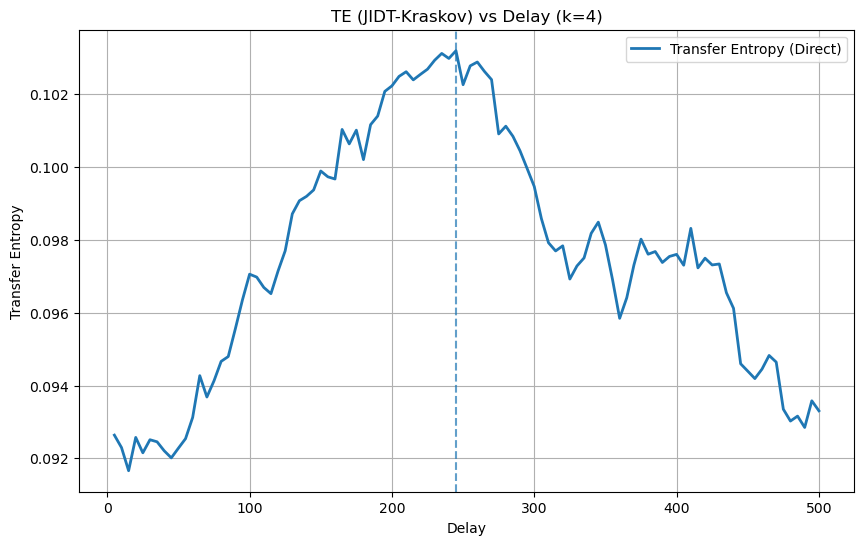

El delay óptimo para k=4 es: 245.000 ms


In [29]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(DP, VPd, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [01:09<00:00,  1.44tau/s]


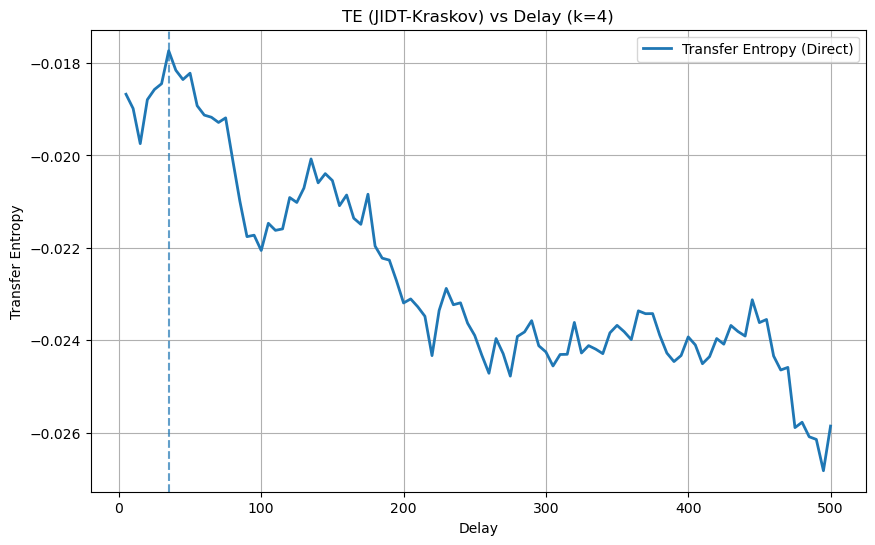

El delay óptimo para k=4 es: 35.000 ms


In [34]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(VPd, PCN, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [01:01<00:00,  1.63tau/s]


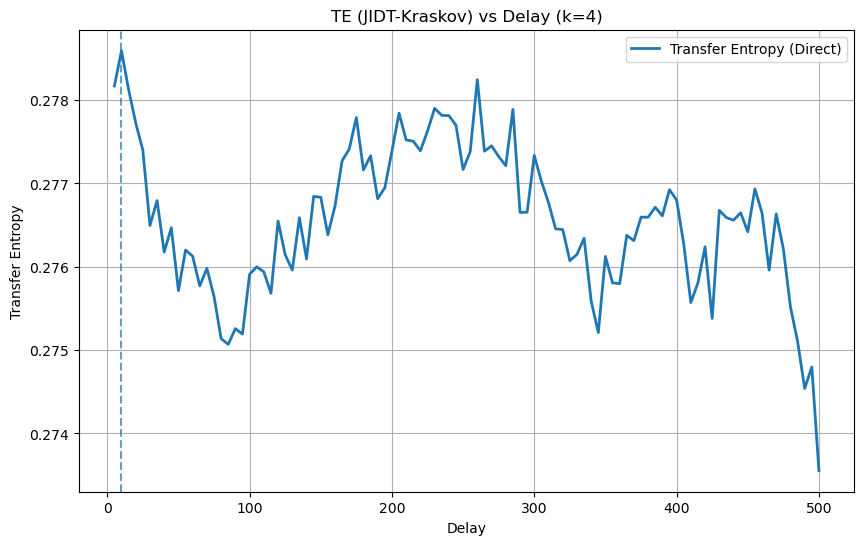

El delay óptimo para k=4 es: 10.000 ms


In [30]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(PCN, VPd, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [01:31<00:00,  1.09tau/s]


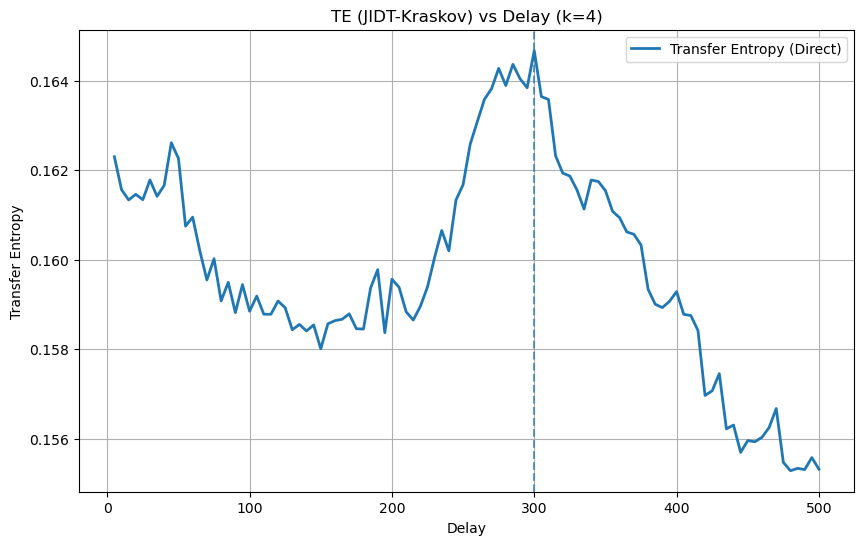

El delay óptimo para k=4 es: 300.000 ms


In [31]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(PCN, CN, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [02:34<00:00,  1.54s/tau]


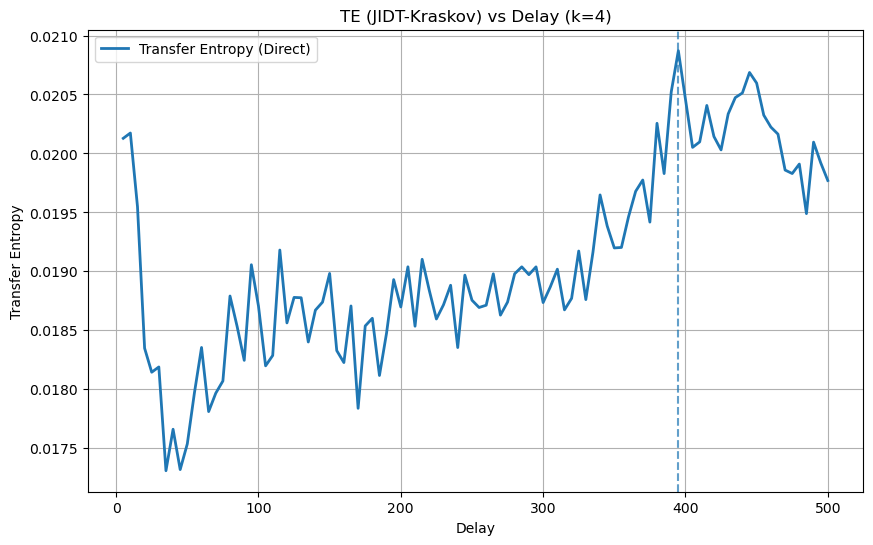

El delay óptimo para k=4 es: 395.000 ms


In [32]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(CN, PCN, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 600/600 [40:38<00:00,  4.06s/tau] 


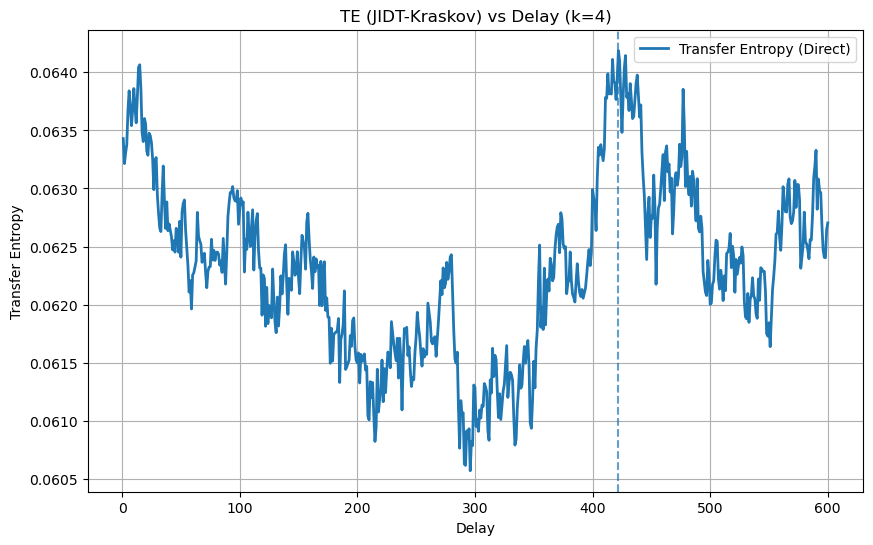

El delay óptimo para k=4 es: 422.000 ms


In [24]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(VPd, CN, n_vecinos=4, max_steps=600, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 90/90 [01:03<00:00,  1.41tau/s]


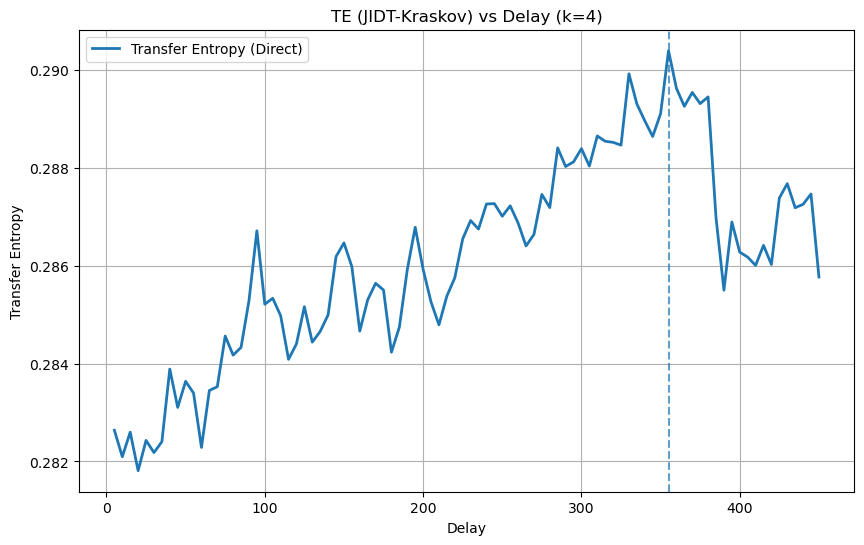

El delay óptimo para k=4 es: 355.000 ms


In [15]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(CN, VPd, n_vecinos=4, max_steps=90, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [02:46<00:00,  1.66s/tau]


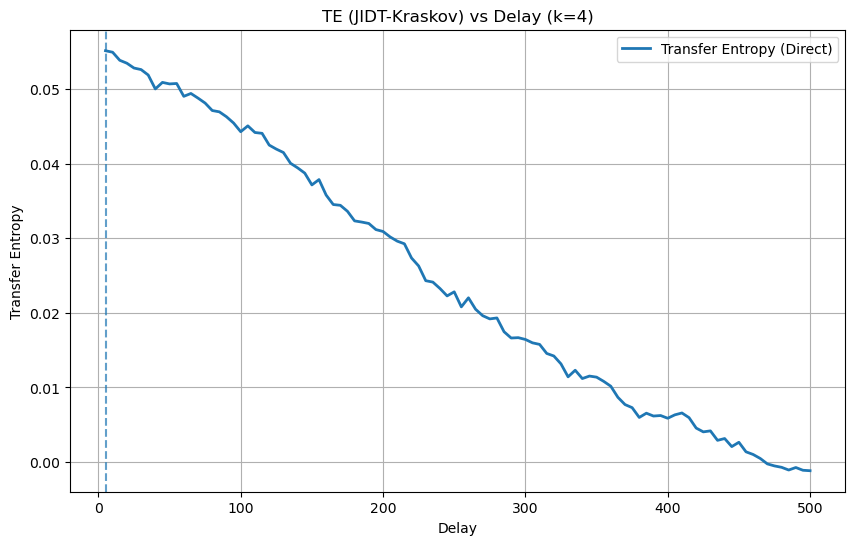

El delay óptimo para k=4 es: 5.000 ms


In [78]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(DP, PCN, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [06:43<00:00,  4.03s/tau]


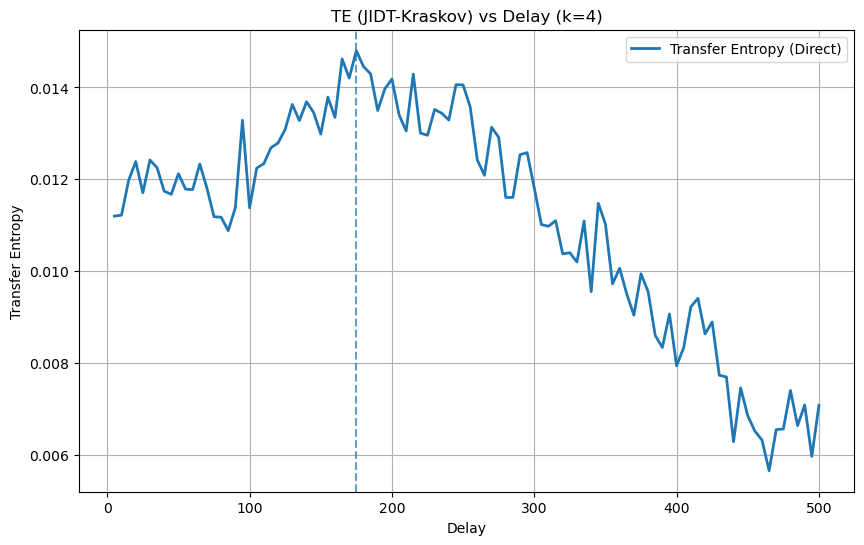

El delay óptimo para k=4 es: 175.000 ms


In [79]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(PCN, DP, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

---

---

In [7]:
def circular_surrogate(x, min_val=1, max_val=1):
    n = len(x)
    high = n - max_val
    if high <= min_val:
        min_val, high = 1, max(2, n - 1)
    shift = np.random.randint(min_val, high)
    return np.roll(x, shift)

TE Original (VPd -> VPd): -0.04395165043494287


Calculando surrogados: 100%|██████████| 100/100 [07:46<00:00,  4.67s/it]


Distribución nula - Media: 0.13341, Std: 0.06478
Pseudo p-valor: 1.0


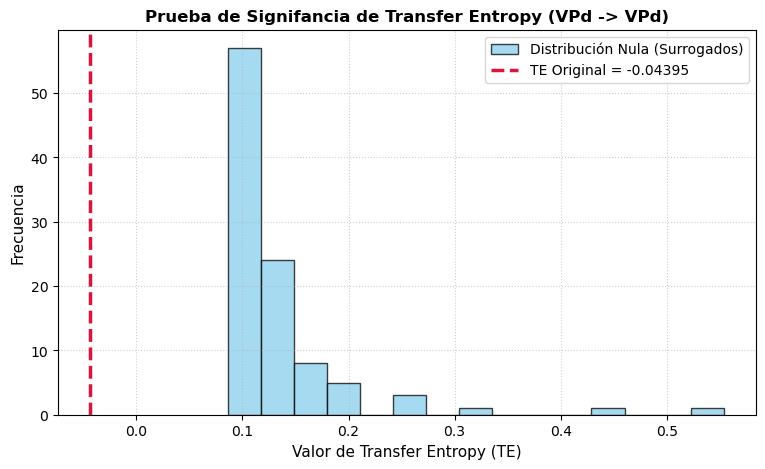

In [80]:
tau=1

VPd = accelerations["VPd"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(VPd.astype(np.float64), VPd.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (VPd -> VPd): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    VPd_surrogate = circular_surrogate(VPd)

    teCalc.initialise()
    teCalc.setObservations(VPd_surrogate.astype(np.float64), VPd.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (VPd -> VPd)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (DP -> DP): -0.007908912637039078


Calculando surrogados: 100%|██████████| 100/100 [2:48:35<00:00, 101.15s/it] 


Distribución nula - Media: 0.00864, Std: 0.01346
Pseudo p-valor: 0.9801980198019802


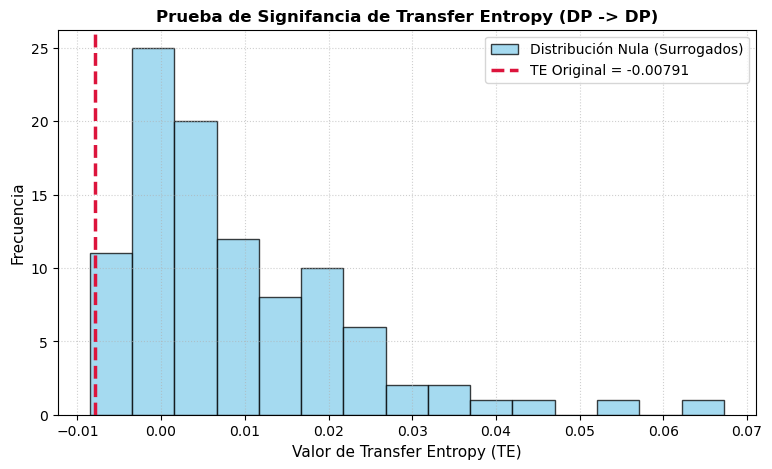

In [81]:
tau=1

DP = accelerations["DP"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(DP.astype(np.float64), DP.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (DP -> DP): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    DP_surrogate = circular_surrogate(DP)

    teCalc.initialise()
    teCalc.setObservations(DP_surrogate.astype(np.float64), DP.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (DP -> DP)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (PCN -> PCN): 0.00835154275754646


Calculando surrogados: 100%|██████████| 100/100 [27:06<00:00, 16.26s/it]


Distribución nula - Media: 0.00504, Std: 0.02667
Pseudo p-valor: 0.297029702970297


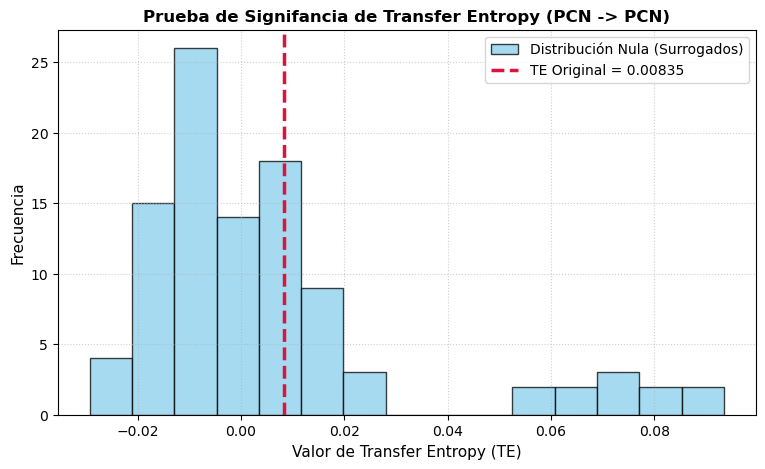

In [82]:
tau=1

PCN = accelerations["PCN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(PCN.astype(np.float64), PCN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (PCN -> PCN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    PCN_surrogate = circular_surrogate(PCN)

    teCalc.initialise()
    teCalc.setObservations(PCN_surrogate.astype(np.float64), PCN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (PCN -> PCN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (CN -> CN): -0.011085180442316878


Calculando surrogados: 100%|██████████| 100/100 [09:22<00:00,  5.63s/it]


Distribución nula - Media: 0.12655, Std: 0.04495
Pseudo p-valor: 1.0


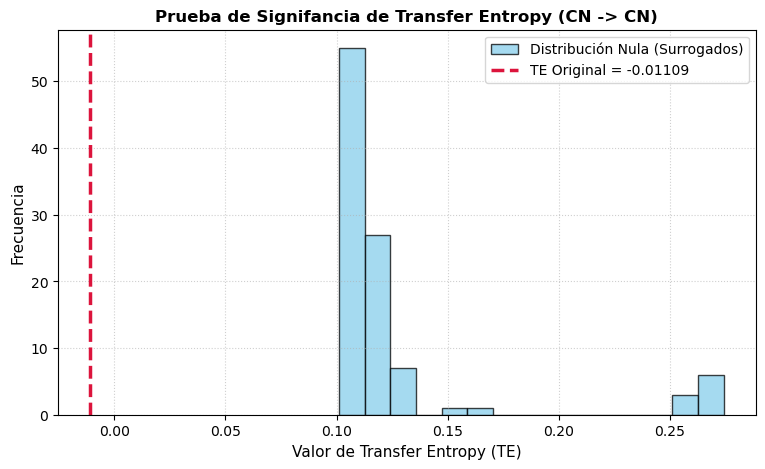

In [83]:
tau=1

CN = accelerations["CN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(CN.astype(np.float64), CN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (CN -> CN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    CN_surrogate = circular_surrogate(CN)

    teCalc.initialise()
    teCalc.setObservations(CN_surrogate.astype(np.float64), CN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (CN -> CN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (VPd -> DP): -0.009272359182091128


Calculando surrogados: 100%|██████████| 100/100 [3:57:42<00:00, 142.63s/it]]


Distribución nula - Media: -0.01173, Std: 0.00376
Pseudo p-valor: 0.22772277227722773


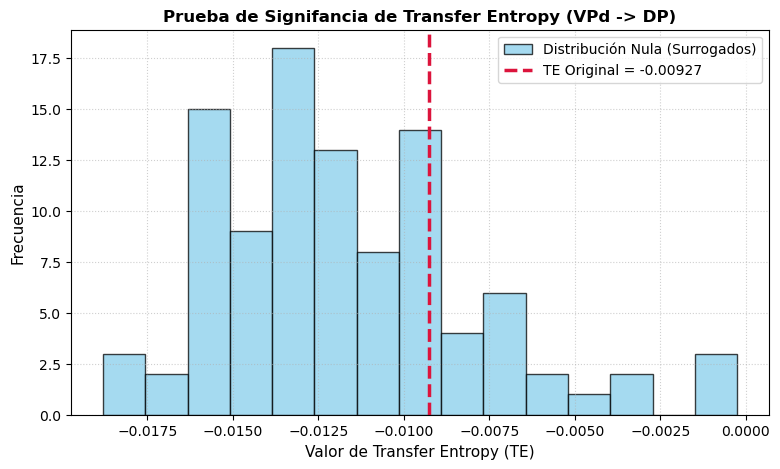

In [35]:
tau=425

VPd = accelerations["VPd"].to_numpy()
DP = accelerations["DP"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(VPd.astype(np.float64), DP.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (VPd -> DP): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    VPd_surrogate = circular_surrogate(VPd)

    teCalc.initialise()
    teCalc.setObservations(VPd_surrogate.astype(np.float64), DP.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (VPd -> DP)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (DP -> VPd): 0.10804732961380026


Calculando surrogados: 100%|██████████| 100/100 [37:54<00:00, 22.74s/it]


Distribución nula - Media: 0.06808, Std: 0.02476
Pseudo p-valor: 0.04950495049504951


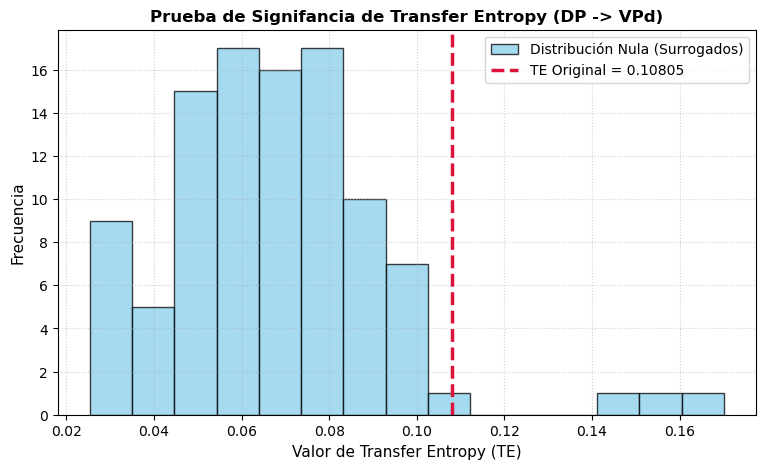

In [36]:
tau=245

DP = accelerations["DP"].to_numpy()
VPd = accelerations["VPd"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(DP.astype(np.float64), VPd.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (DP -> VPd): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    DP_surrogate = circular_surrogate(DP)

    teCalc.initialise()
    teCalc.setObservations(DP_surrogate.astype(np.float64), VPd.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (DP -> VPd)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (VPd -> PCN): -0.01150936313294415


Calculando surrogados: 100%|██████████| 100/100 [20:33<00:00, 12.34s/it]


Distribución nula - Media: -0.00933, Std: 0.00263
Pseudo p-valor: 0.7920792079207921


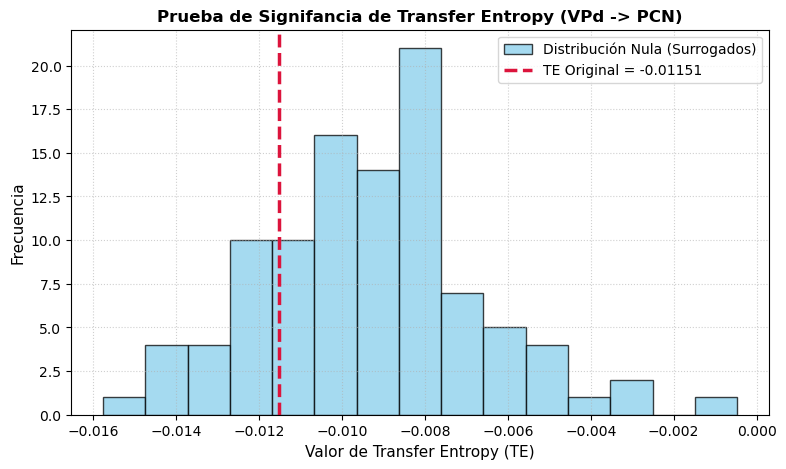

In [37]:
tau=35

VPd = accelerations["VPd"].to_numpy()
PCN = accelerations["PCN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(VPd.astype(np.float64), PCN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (VPd -> PCN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    VPd_surrogate = circular_surrogate(VPd)

    teCalc.initialise()
    teCalc.setObservations(VPd_surrogate.astype(np.float64), PCN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (VPd -> PCN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (PCN -> VPd): 0.21942613180375847


Calculando surrogados: 100%|██████████| 100/100 [07:16<00:00,  4.37s/it]


Distribución nula - Media: 0.19171, Std: 0.03733
Pseudo p-valor: 0.1485148514851485


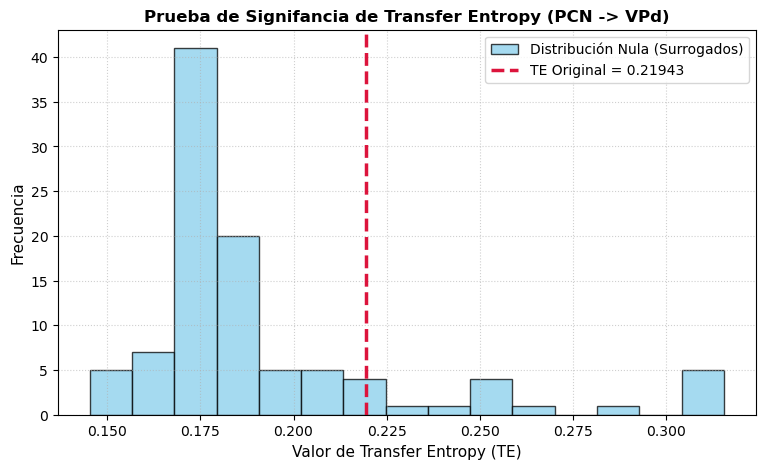

In [38]:
tau=260

PCN = accelerations["PCN"].to_numpy()
VPd = accelerations["VPd"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(PCN.astype(np.float64), VPd.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (PCN -> VPd): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    PCN_surrogate = circular_surrogate(PCN)

    teCalc.initialise()
    teCalc.setObservations(PCN_surrogate.astype(np.float64), VPd.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (PCN -> VPd)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (VPd -> CN): 0.06397887312820716


Calculando surrogados: 100%|██████████| 100/100 [06:21<00:00,  3.81s/it]


Distribución nula - Media: 0.06595, Std: 0.00451
Pseudo p-valor: 0.693069306930693


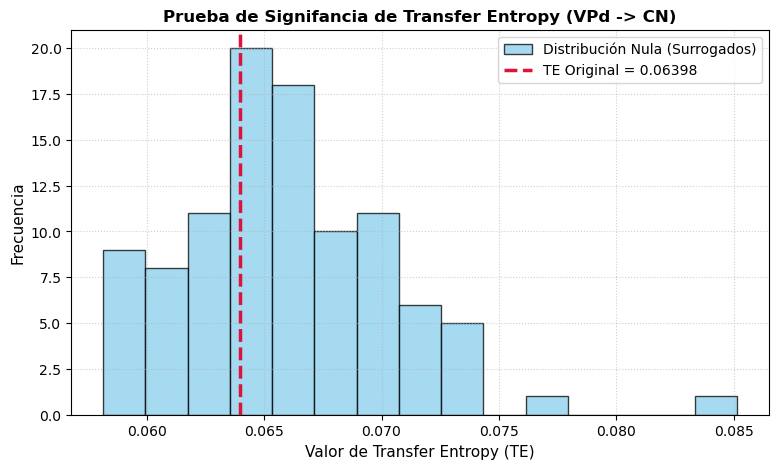

In [39]:
tau=422

VPd = accelerations["VPd"].to_numpy()
CN = accelerations["CN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(VPd.astype(np.float64), CN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (VPd -> CN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    VPd_surrogate = circular_surrogate(VPd)

    teCalc.initialise()
    teCalc.setObservations(VPd_surrogate.astype(np.float64), CN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (VPd -> CN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (CN -> VPd): 0.24886577790369024


Calculando surrogados: 100%|██████████| 100/100 [05:56<00:00,  3.57s/it]


Distribución nula - Media: 0.19516, Std: 0.01782
Pseudo p-valor: 0.0297029702970297


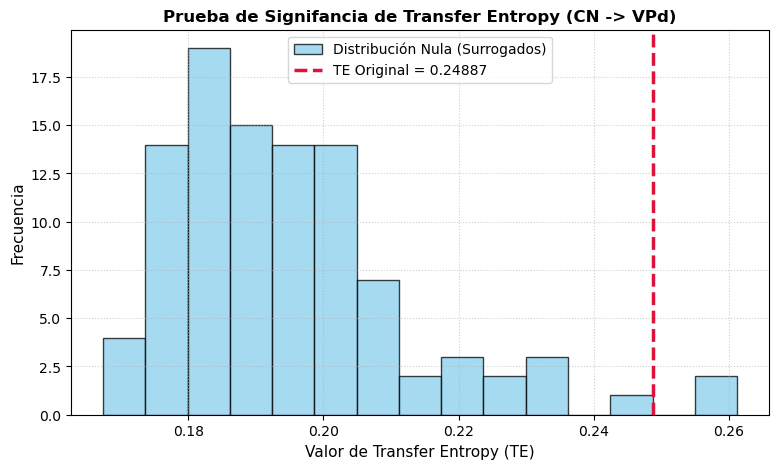

In [40]:
tau=355

CN = accelerations["CN"].to_numpy()
VPd = accelerations["VPd"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(CN.astype(np.float64), VPd.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (CN -> VPd): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    CN_surrogate = circular_surrogate(CN)

    teCalc.initialise()
    teCalc.setObservations(CN_surrogate.astype(np.float64), VPd.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (CN -> VPd)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (DP -> CN): 0.15861288241496685


Calculando surrogados: 100%|██████████| 100/100 [44:24<00:00, 26.64s/it]


Distribución nula - Media: 0.02883, Std: 0.03688
Pseudo p-valor: 0.019801980198019802


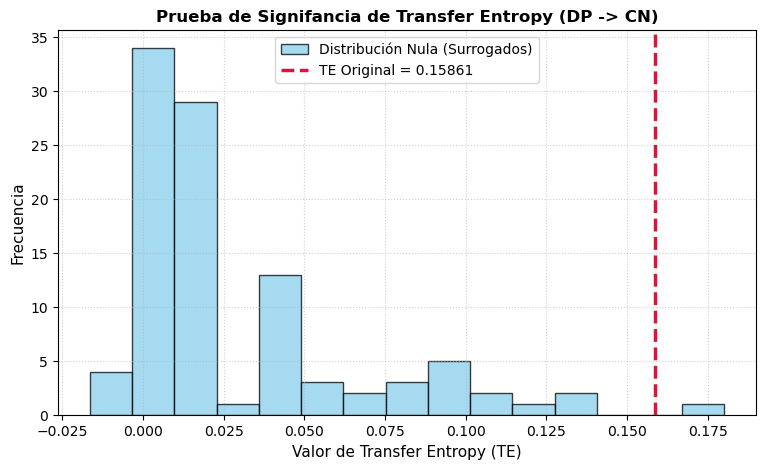

In [33]:
tau=390

DP = accelerations["DP"].to_numpy()
CN = accelerations["CN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(DP.astype(np.float64), CN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (DP -> CN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    DP_surrogate = circular_surrogate(DP)

    teCalc.initialise()
    teCalc.setObservations(DP_surrogate.astype(np.float64), CN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (DP -> CN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (CN -> DP): 0.006450412345260004


Calculando surrogados: 100%|██████████| 100/100 [3:06:57<00:00, 112.18s/it] 


Distribución nula - Media: 0.00720, Std: 0.00506
Pseudo p-valor: 0.5841584158415841


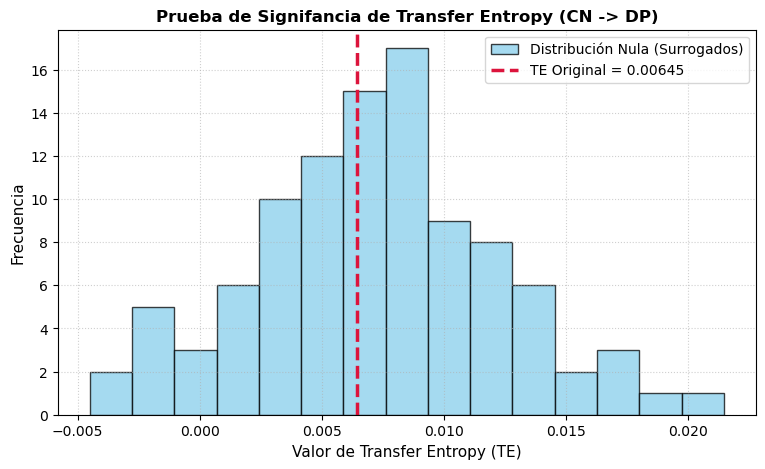

In [37]:
tau=285

CN = accelerations["CN"].to_numpy()
DP = accelerations["DP"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(CN.astype(np.float64), DP.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (CN -> DP): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    CN_surrogate = circular_surrogate(CN)

    teCalc.initialise()
    teCalc.setObservations(CN_surrogate.astype(np.float64), DP.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (CN -> DP)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (PCN -> CN): 0.11230659291719625


Calculando surrogados: 100%|██████████| 100/100 [3:47:19<00:00, 136.40s/it]   


Distribución nula - Media: 0.10352, Std: 0.01729
Pseudo p-valor: 0.15841584158415842


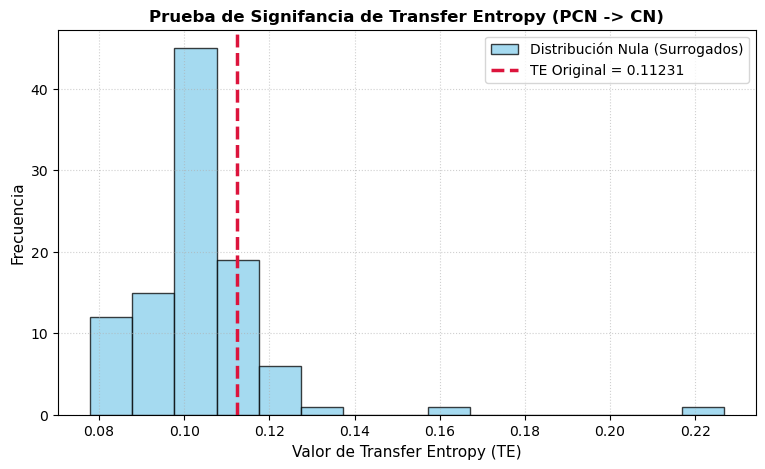

In [38]:
tau=300

PCN = accelerations["PCN"].to_numpy()
CN = accelerations["CN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(PCN.astype(np.float64), CN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (PCN -> CN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    PCN_surrogate = circular_surrogate(PCN)

    teCalc.initialise()
    teCalc.setObservations(PCN_surrogate.astype(np.float64), CN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (PCN -> CN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (CN -> PCN): 0.019737219222479174


Calculando surrogados: 100%|██████████| 100/100 [20:03<00:00, 12.04s/it]


Distribución nula - Media: -0.00143, Std: 0.01663
Pseudo p-valor: 0.0594059405940594


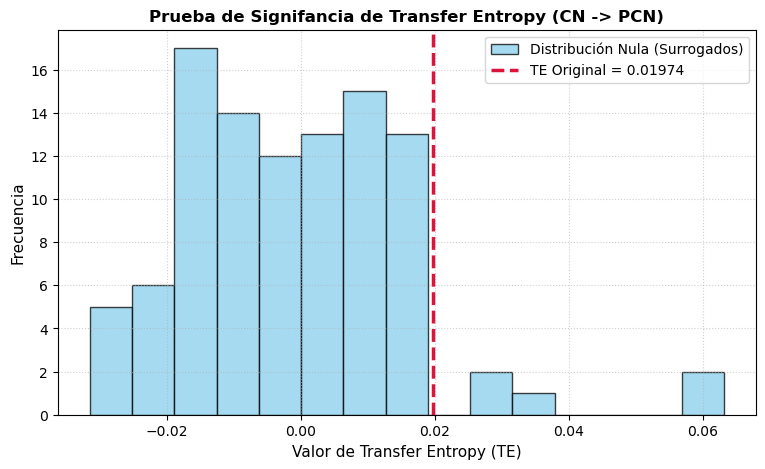

In [39]:
tau=395

CN = accelerations["CN"].to_numpy()
PCN = accelerations["PCN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(CN.astype(np.float64), PCN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (CN -> PCN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    CN_surrogate = circular_surrogate(CN)

    teCalc.initialise()
    teCalc.setObservations(CN_surrogate.astype(np.float64), PCN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (CN -> PCN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (DP -> PCN): 0.03815384322419546


Calculando surrogados: 100%|██████████| 100/100 [40:58<00:00, 24.58s/it]


Distribución nula - Media: -0.01167, Std: 0.01070
Pseudo p-valor: 0.019801980198019802


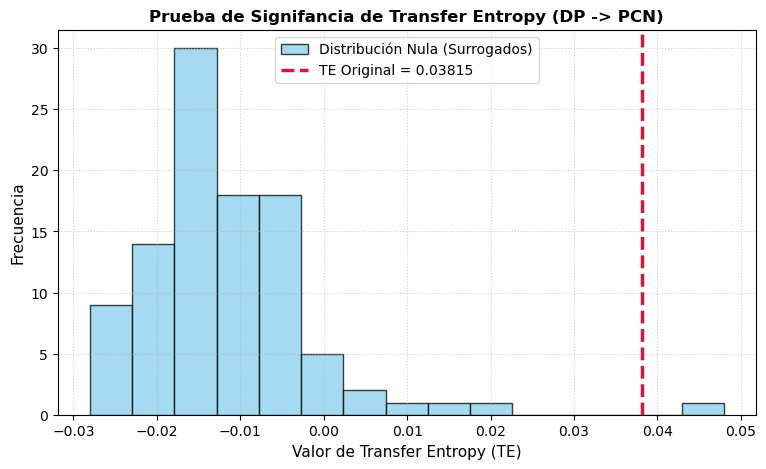

In [84]:
tau=5

DP = accelerations["DP"].to_numpy()
PCN = accelerations["PCN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(DP.astype(np.float64), PCN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (DP -> PCN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    DP_surrogate = circular_surrogate(DP)

    teCalc.initialise()
    teCalc.setObservations(DP_surrogate.astype(np.float64), PCN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (DP -> PCN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (PCN -> DP): 0.004650161068036951


Calculando surrogados: 100%|██████████| 100/100 [2:39:22<00:00, 95.62s/it]  


Distribución nula - Media: 0.01654, Std: 0.00799
Pseudo p-valor: 0.9603960396039604


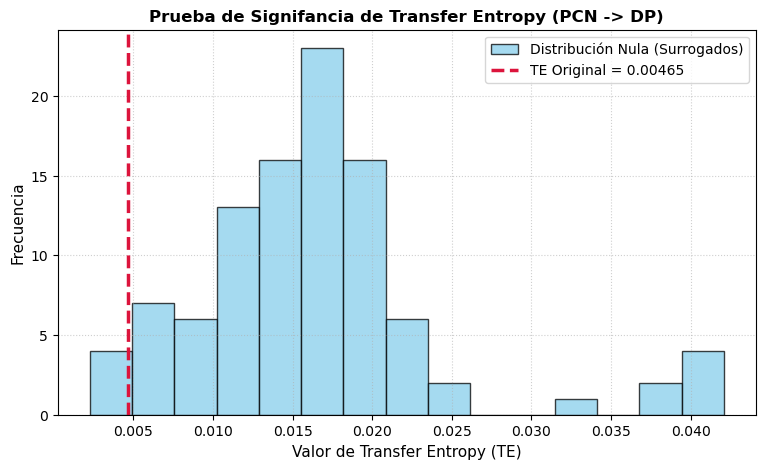

In [85]:
tau=175

PCN = accelerations["PCN"].to_numpy()
DP = accelerations["DP"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(PCN.astype(np.float64), DP.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (PCN -> DP): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    PCN_surrogate = circular_surrogate(PCN)

    teCalc.initialise()
    teCalc.setObservations(PCN_surrogate.astype(np.float64), DP.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (PCN -> DP)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

---

---

## CESSATIONS

In [117]:
data2 = pd.read_csv("SGA_cess.txt", sep=r"\s+", header=None)
cessations = data2.iloc[:, -4:].copy()
cessations.columns = ["VPd", "DP", "PCN", "CN"]

cessations.head()

,VPd,DP,PCN,CN
0,-65.0912,-63.635,-64.4749,-64.8126
1,-65.0843,-63.635,-64.4671,-64.8124
2,-65.0774,-63.635,-64.4594,-64.8122
3,-65.0704,-63.635,-64.4516,-64.8120
4,-65.0635,-63.635,-64.4438,-64.8118


In [118]:
DP = cessations["DP"].to_numpy()
CN = cessations["CN"].to_numpy()
VPd = cessations["VPd"].to_numpy()
PCN = cessations["PCN"].to_numpy()

Análisis de Tau: 100%|██████████| 100/100 [01:04<00:00,  1.54tau/s]


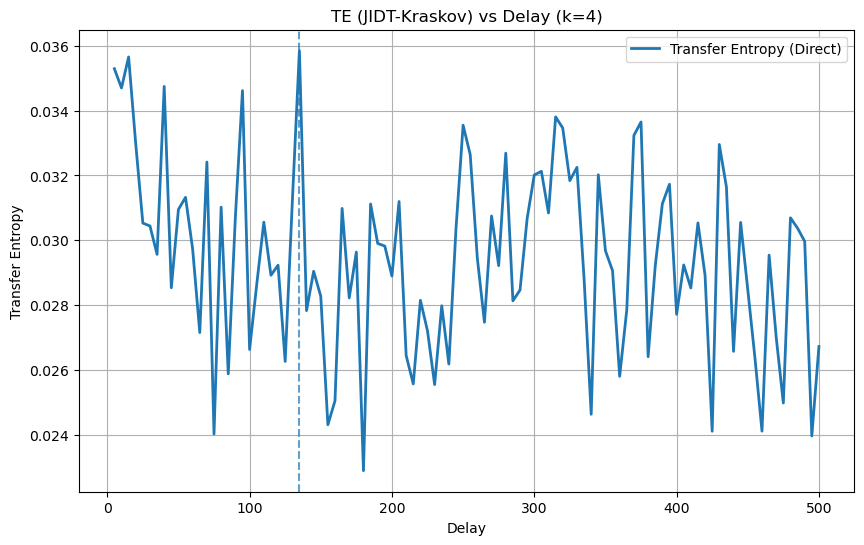

El delay óptimo para k=4 es: 135.000 ms


In [11]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(DP, CN, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [03:23<00:00,  2.03s/tau]


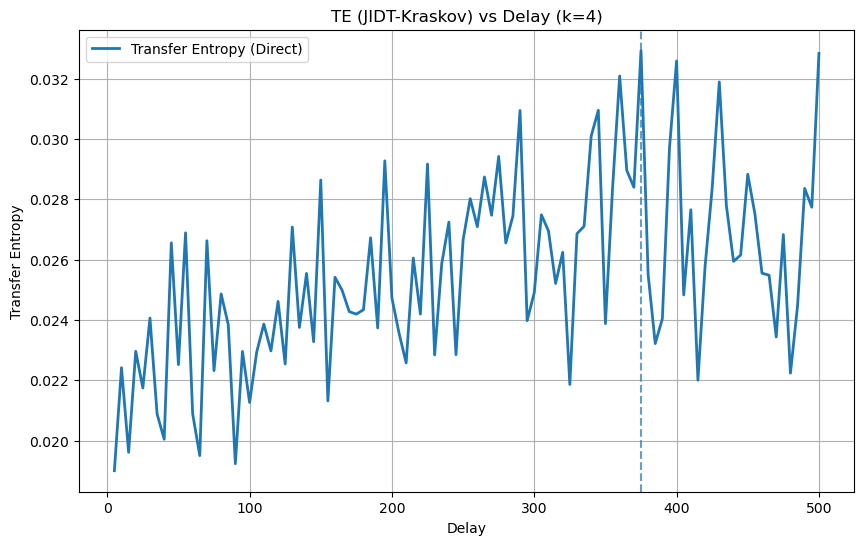

El delay óptimo para k=4 es: 375.000 ms


In [12]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(CN, DP, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [05:02<00:00,  3.03s/tau]


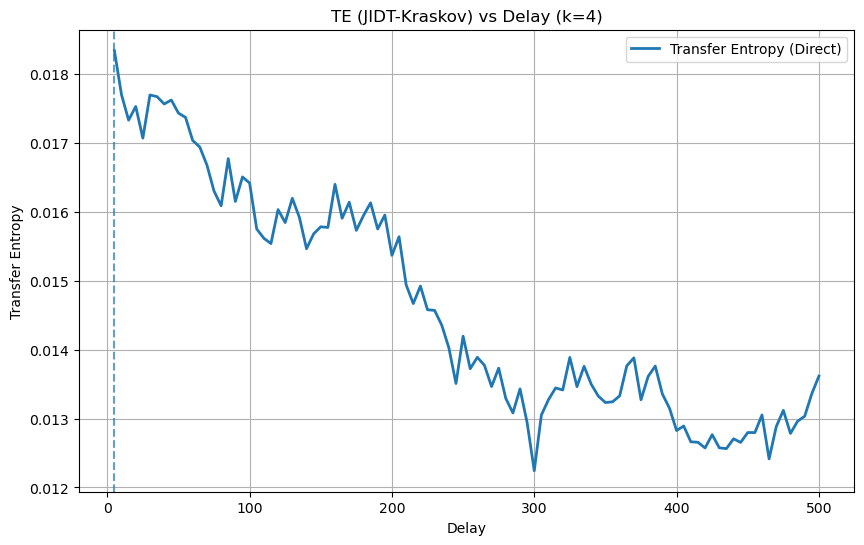

El delay óptimo para k=4 es: 5.000 ms


In [13]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(VPd, DP, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 150/150 [01:40<00:00,  1.49tau/s]


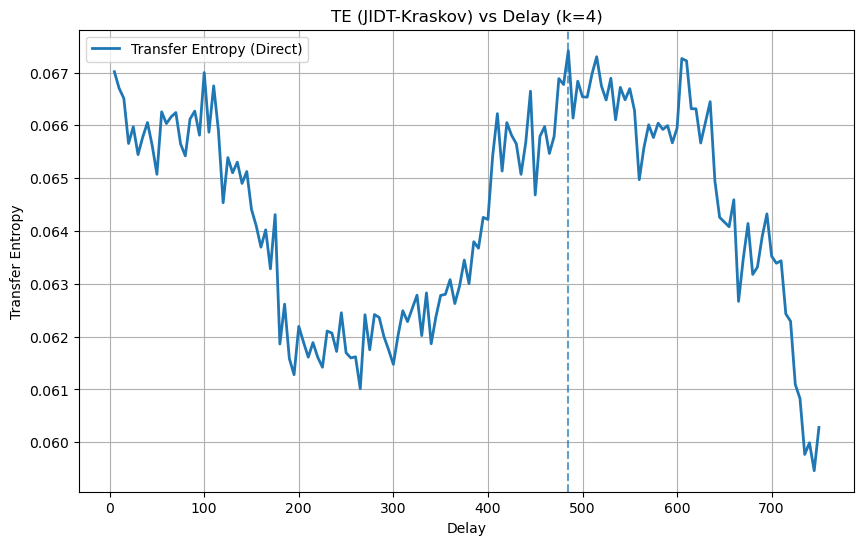

El delay óptimo para k=4 es: 485.000 ms


In [18]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(DP, VPd, n_vecinos=4, max_steps=150, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [00:57<00:00,  1.74tau/s]


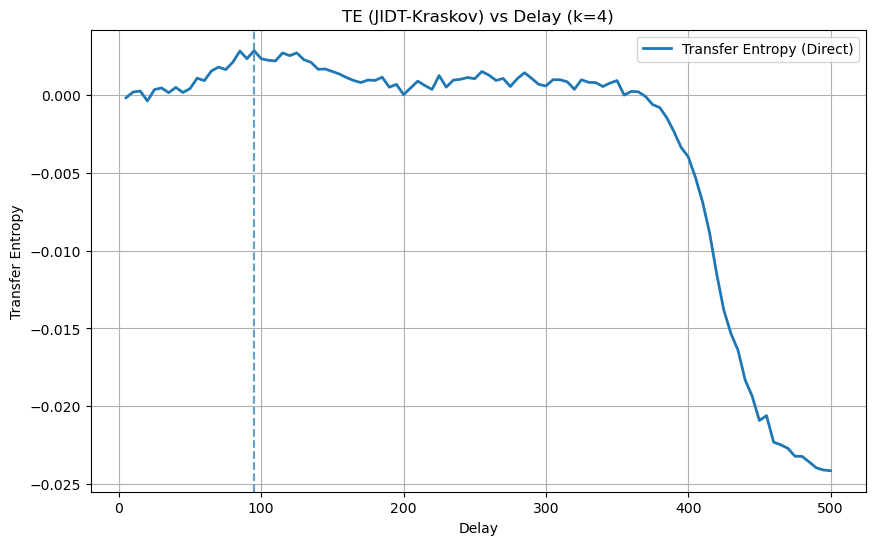

El delay óptimo para k=4 es: 95.000 ms


In [19]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(VPd, PCN, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [00:35<00:00,  2.80tau/s]


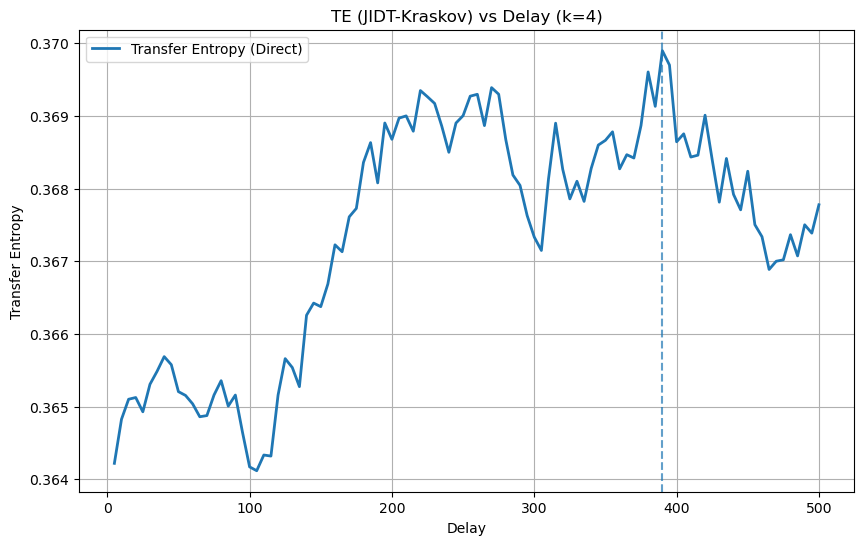

El delay óptimo para k=4 es: 390.000 ms


In [15]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(PCN, VPd, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [01:04<00:00,  1.55tau/s]


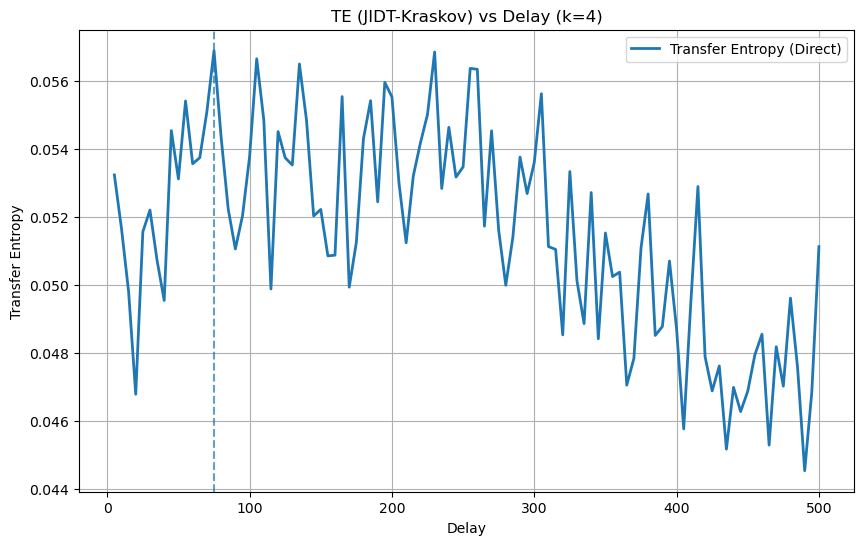

El delay óptimo para k=4 es: 75.000 ms


In [16]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(PCN, CN, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [00:48<00:00,  2.05tau/s]


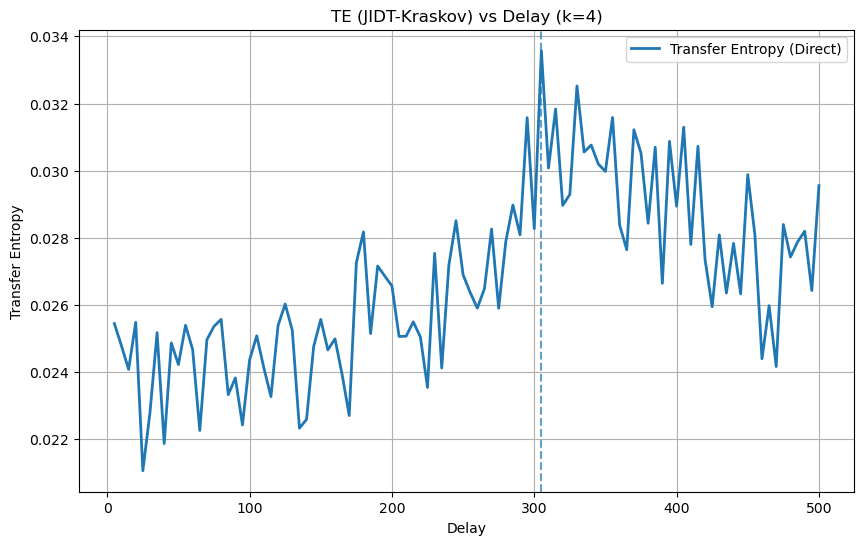

El delay óptimo para k=4 es: 305.000 ms


In [17]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(CN, PCN, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 600/600 [2:03:07<00:00, 12.31s/tau]  


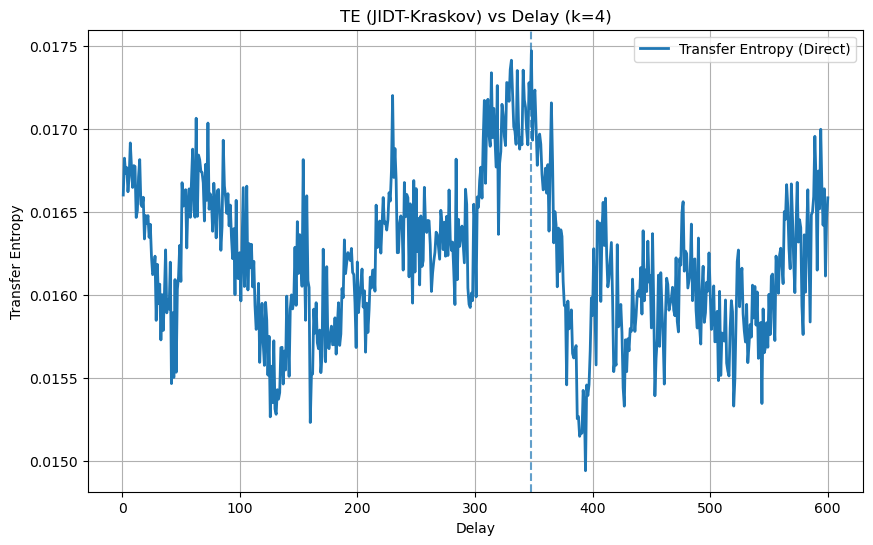

El delay óptimo para k=4 es: 348.000 ms


In [35]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(VPd, CN, n_vecinos=4, max_steps=600, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 90/90 [00:35<00:00,  2.55tau/s]


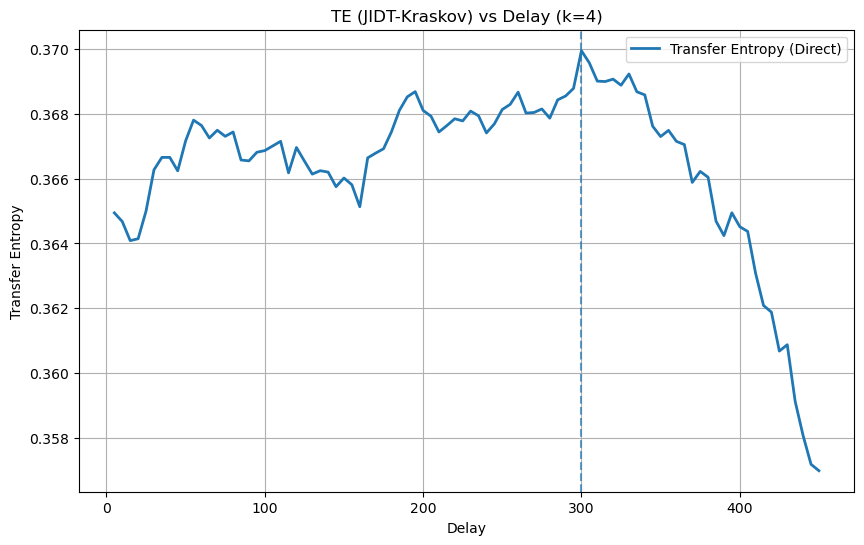

El delay óptimo para k=4 es: 300.000 ms


In [10]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(CN, VPd, n_vecinos=4, max_steps=90, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [01:33<00:00,  1.08tau/s]


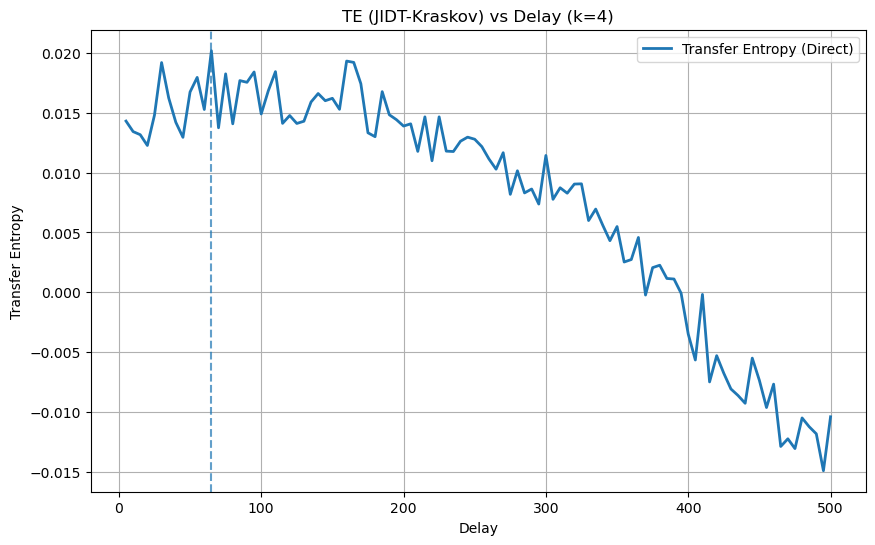

El delay óptimo para k=4 es: 65.000 ms


In [107]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(DP, PCN, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [04:42<00:00,  2.83s/tau]


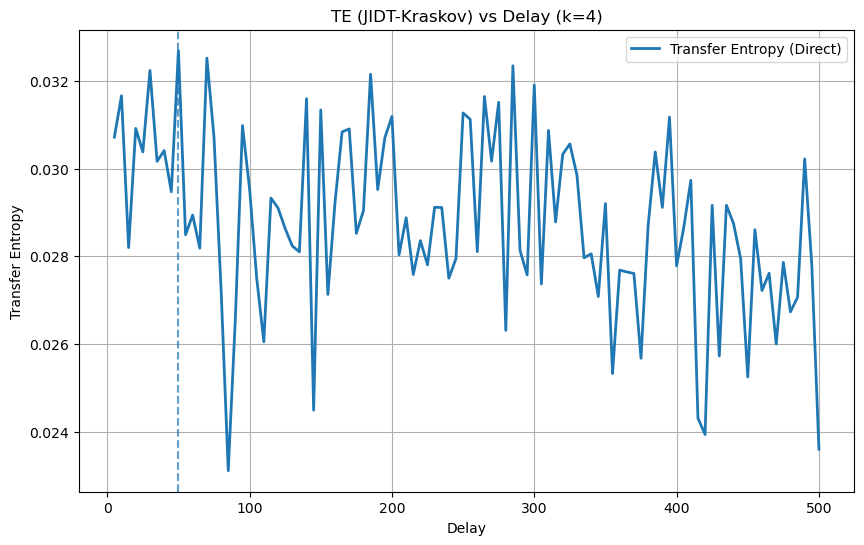

El delay óptimo para k=4 es: 50.000 ms


In [108]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(PCN, DP, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

---

---

TE Original (VPd -> VPd): -0.04465256552665875


Calculando surrogados: 100%|██████████| 100/100 [03:02<00:00,  1.83s/it]


Distribución nula - Media: 0.12936, Std: 0.02722
Pseudo p-valor: 1.0


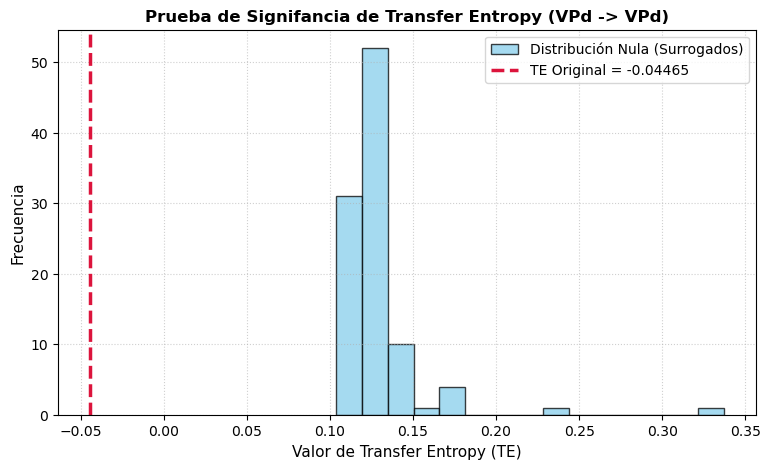

In [88]:
tau=1

VPd = cessations["VPd"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(VPd.astype(np.float64), VPd.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (VPd -> VPd): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    VPd_surrogate = circular_surrogate(VPd)

    teCalc.initialise()
    teCalc.setObservations(VPd_surrogate.astype(np.float64), VPd.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (VPd -> VPd)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (DP -> DP): -0.006327475686592976


Calculando surrogados: 100%|██████████| 100/100 [19:41<00:00, 11.81s/it]


Distribución nula - Media: 0.00205, Std: 0.00343
Pseudo p-valor: 1.0


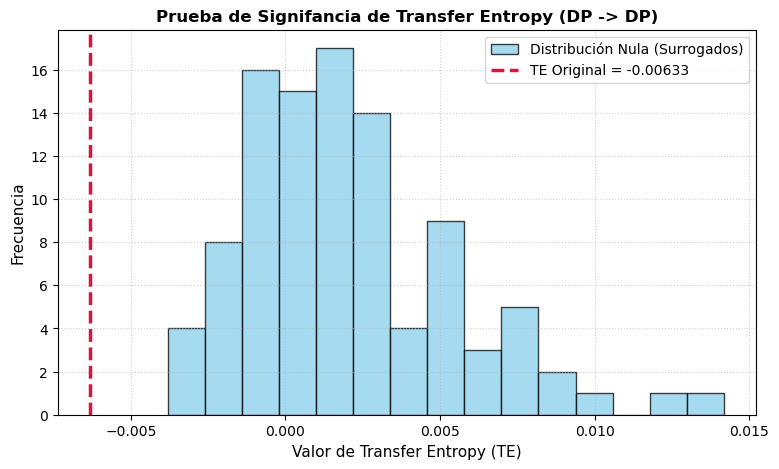

In [89]:
tau=1

DP = cessations["DP"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(DP.astype(np.float64), DP.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (DP -> DP): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    DP_surrogate = circular_surrogate(DP)

    teCalc.initialise()
    teCalc.setObservations(DP_surrogate.astype(np.float64), DP.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (DP -> DP)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (PCN -> PCN): 0.002094284294789528


Calculando surrogados: 100%|██████████| 100/100 [08:24<00:00,  5.04s/it]


Distribución nula - Media: 0.01222, Std: 0.01779
Pseudo p-valor: 0.6633663366336634


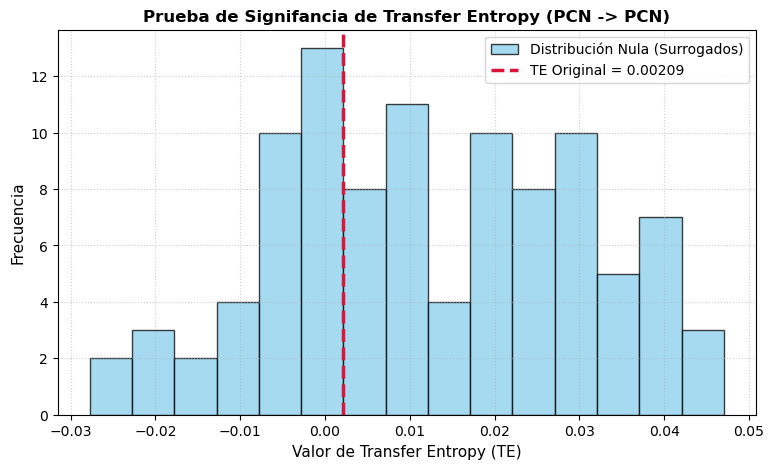

In [90]:
tau=1

PCN = cessations["PCN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(PCN.astype(np.float64), PCN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (PCN -> PCN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    PCN_surrogate = circular_surrogate(PCN)

    teCalc.initialise()
    teCalc.setObservations(PCN_surrogate.astype(np.float64), PCN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (PCN -> PCN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (CN -> CN): -0.0016819600448785277


Calculando surrogados: 100%|██████████| 100/100 [15:31<00:00,  9.31s/it]


Distribución nula - Media: 0.01892, Std: 0.03263
Pseudo p-valor: 0.7029702970297029


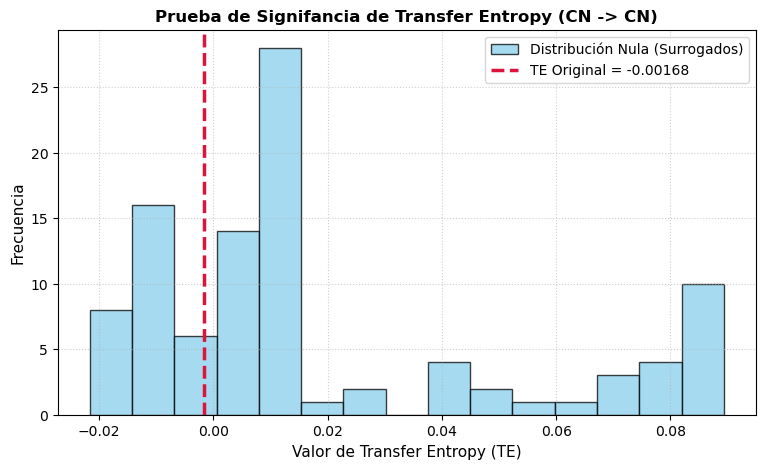

In [91]:
tau=1

CN = cessations["CN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(CN.astype(np.float64), CN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (CN -> CN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    CN_surrogate = circular_surrogate(CN)

    teCalc.initialise()
    teCalc.setObservations(CN_surrogate.astype(np.float64), CN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (CN -> CN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (VPd -> DP): 0.01667424883278157


Calculando surrogados: 100%|██████████| 100/100 [1:44:56<00:00, 62.96s/it]


Distribución nula - Media: 0.01646, Std: 0.00139
Pseudo p-valor: 0.44554455445544555


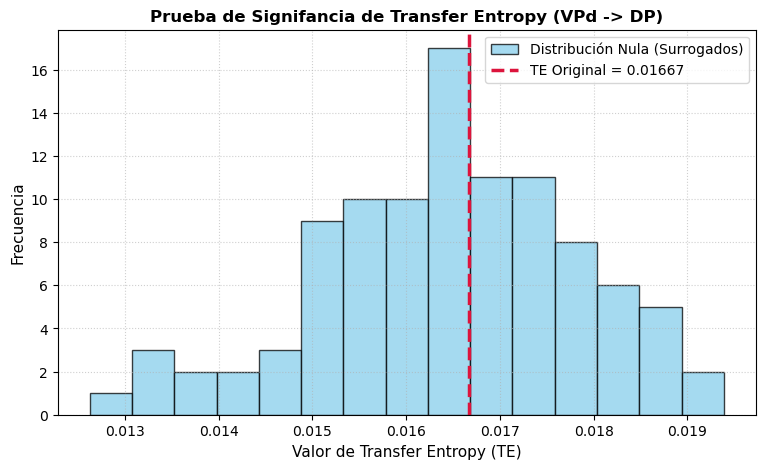

In [42]:
tau=5

VPd = cessations["VPd"].to_numpy()
DP = cessations["DP"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(VPd.astype(np.float64), DP.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (VPd -> DP): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    VPd_surrogate = circular_surrogate(VPd)

    teCalc.initialise()
    teCalc.setObservations(VPd_surrogate.astype(np.float64), DP.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (VPd -> DP)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (DP -> VPd): 0.07160096794229065


Calculando surrogados: 100%|██████████| 100/100 [14:53<00:00,  8.93s/it]


Distribución nula - Media: 0.04377, Std: 0.01883
Pseudo p-valor: 0.09900990099009901


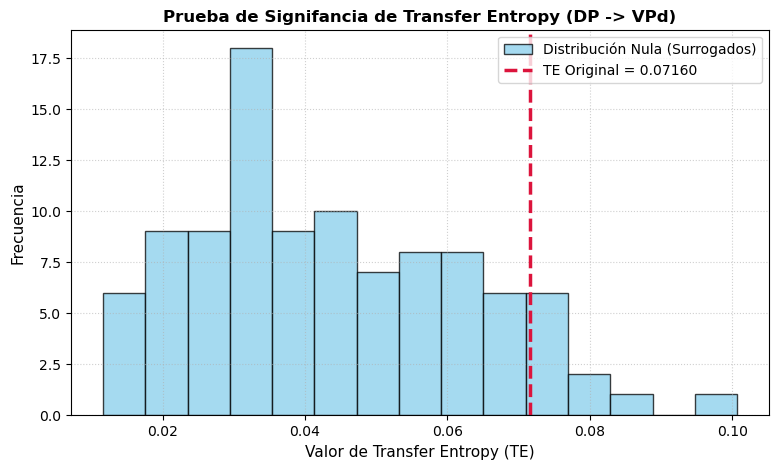

In [43]:
tau=485

DP = cessations["DP"].to_numpy()
VPd = cessations["VPd"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(DP.astype(np.float64), VPd.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (DP -> VPd): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    DP_surrogate = circular_surrogate(DP)

    teCalc.initialise()
    teCalc.setObservations(DP_surrogate.astype(np.float64), VPd.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (DP -> VPd)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (VPd -> PCN): 0.0003030610845764503


Calculando surrogados: 100%|██████████| 100/100 [08:55<00:00,  5.35s/it]


Distribución nula - Media: 0.00474, Std: 0.00258
Pseudo p-valor: 0.9801980198019802


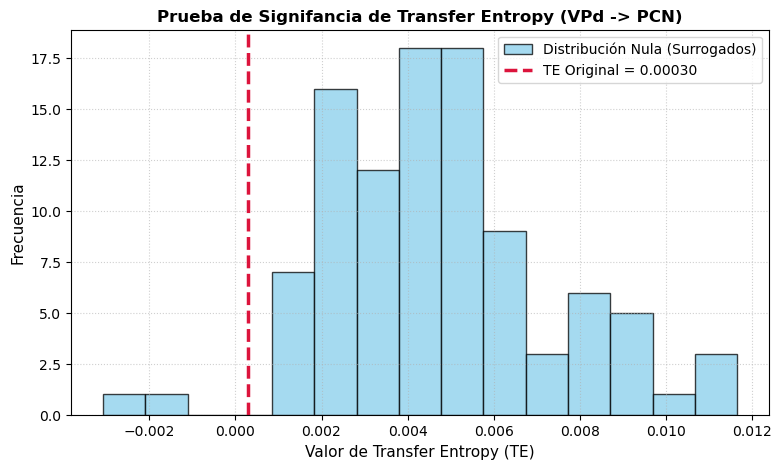

In [44]:
tau=95

VPd = cessations["VPd"].to_numpy()
PCN = cessations["PCN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(VPd.astype(np.float64), PCN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (VPd -> PCN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    VPd_surrogate = circular_surrogate(VPd)

    teCalc.initialise()
    teCalc.setObservations(VPd_surrogate.astype(np.float64), PCN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (VPd -> PCN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (PCN -> VPd): 0.34624856316957153


Calculando surrogados: 100%|██████████| 100/100 [03:20<00:00,  2.01s/it]


Distribución nula - Media: 0.24412, Std: 0.05524
Pseudo p-valor: 0.07920792079207921


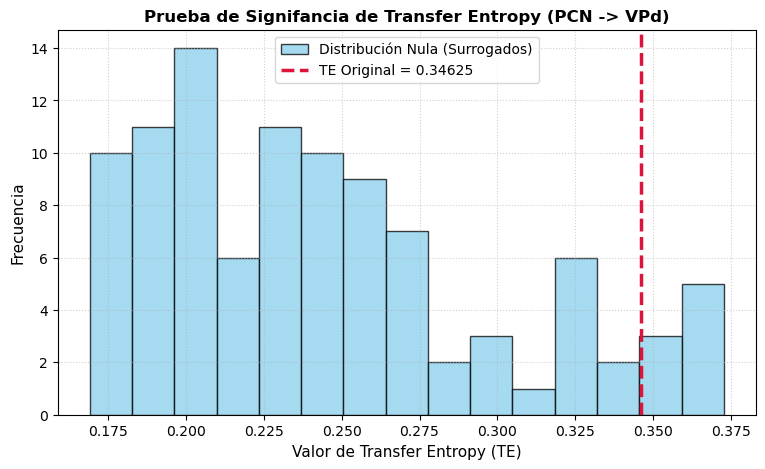

In [45]:
tau=390

PCN = cessations["PCN"].to_numpy()
VPd = cessations["VPd"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(PCN.astype(np.float64), VPd.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (PCN -> VPd): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    PCN_surrogate = circular_surrogate(PCN)

    teCalc.initialise()
    teCalc.setObservations(PCN_surrogate.astype(np.float64), VPd.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (PCN -> VPd)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (VPd -> CN): 0.017265118226145626


Calculando surrogados: 100%|██████████| 100/100 [19:12<00:00, 11.52s/it]


Distribución nula - Media: 0.02217, Std: 0.00309
Pseudo p-valor: 0.9702970297029703


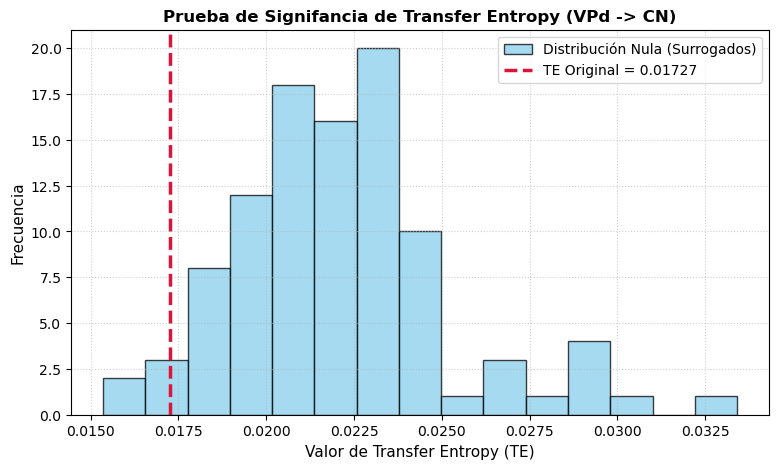

In [46]:
tau=348

VPd = cessations["VPd"].to_numpy()
CN = cessations["CN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(VPd.astype(np.float64), CN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (VPd -> CN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    VPd_surrogate = circular_surrogate(VPd)

    teCalc.initialise()
    teCalc.setObservations(VPd_surrogate.astype(np.float64), CN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (VPd -> CN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (CN -> VPd): 0.38134363887358336


Calculando surrogados: 100%|██████████| 100/100 [04:00<00:00,  2.41s/it]


Distribución nula - Media: 0.22246, Std: 0.06575
Pseudo p-valor: 0.019801980198019802


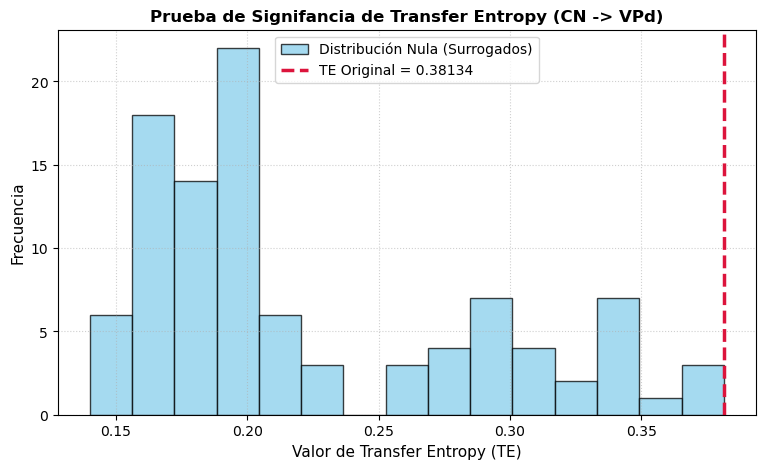

In [47]:
tau=300

CN = cessations["CN"].to_numpy()
VPd = cessations["VPd"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(CN.astype(np.float64), VPd.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (CN -> VPd): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    CN_surrogate = circular_surrogate(CN)

    teCalc.initialise()
    teCalc.setObservations(CN_surrogate.astype(np.float64), VPd.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (CN -> VPd)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (DP -> CN): 0.02210338221469277


Calculando surrogados: 100%|██████████| 100/100 [14:03<00:00,  8.44s/it]


Distribución nula - Media: -0.00545, Std: 0.00913
Pseudo p-valor: 0.0297029702970297


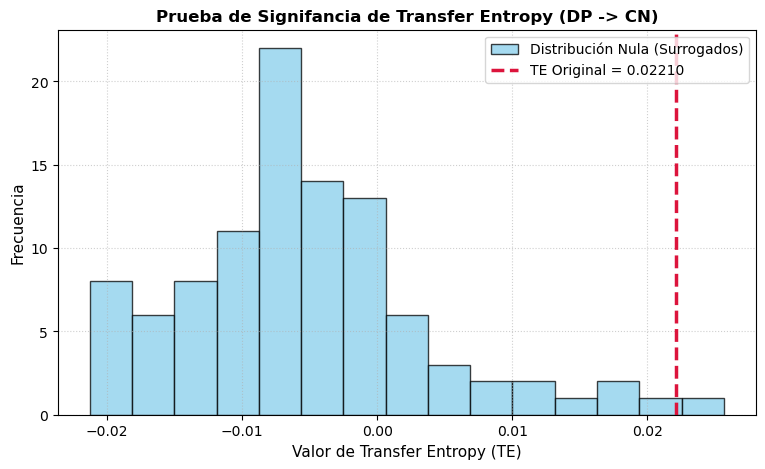

In [48]:
tau=135

DP = cessations["DP"].to_numpy()
CN = cessations["CN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(DP.astype(np.float64), CN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (DP -> CN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    DP_surrogate = circular_surrogate(DP)

    teCalc.initialise()
    teCalc.setObservations(DP_surrogate.astype(np.float64), CN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (DP -> CN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (CN -> DP): 0.01937322179772316


Calculando surrogados: 100%|██████████| 100/100 [1:09:38<00:00, 41.78s/it]


Distribución nula - Media: 0.01020, Std: 0.00392
Pseudo p-valor: 0.0297029702970297


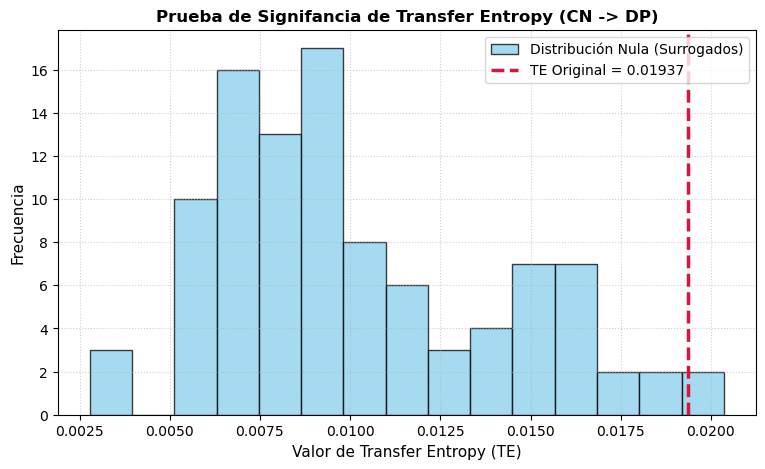

In [49]:
tau=375

CN = cessations["CN"].to_numpy()
DP = cessations["DP"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(CN.astype(np.float64), DP.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (CN -> DP): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    CN_surrogate = circular_surrogate(CN)

    teCalc.initialise()
    teCalc.setObservations(CN_surrogate.astype(np.float64), DP.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (CN -> DP)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (PCN -> CN): 0.024679756587626


Calculando surrogados: 100%|██████████| 100/100 [17:26<00:00, 10.46s/it]


Distribución nula - Media: 0.01324, Std: 0.01633
Pseudo p-valor: 0.297029702970297


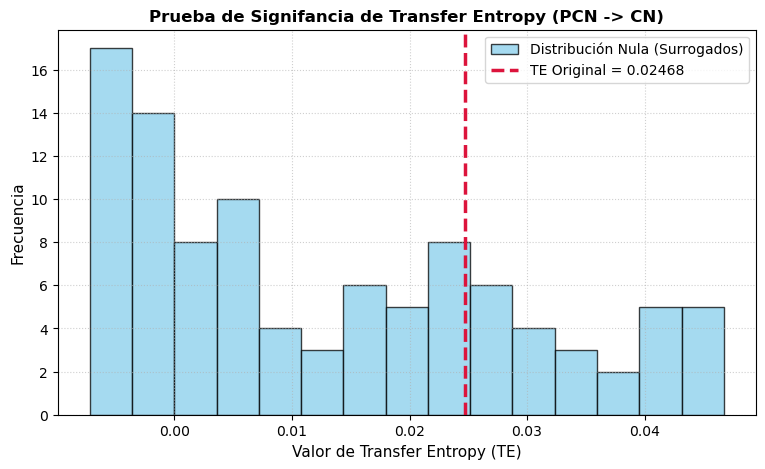

In [50]:
tau=75

PCN = cessations["PCN"].to_numpy()
CN = cessations["CN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(PCN.astype(np.float64), CN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (PCN -> CN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    PCN_surrogate = circular_surrogate(PCN)

    teCalc.initialise()
    teCalc.setObservations(PCN_surrogate.astype(np.float64), CN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (PCN -> CN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (CN -> PCN): 0.035502181379775566


Calculando surrogados: 100%|██████████| 100/100 [09:30<00:00,  5.71s/it]


Distribución nula - Media: 0.00215, Std: 0.01743
Pseudo p-valor: 0.039603960396039604


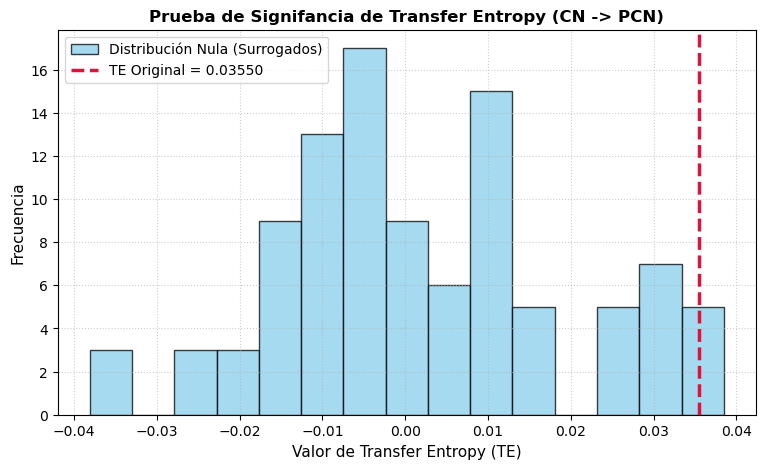

In [51]:
tau=305

CN = cessations["CN"].to_numpy()
PCN = cessations["PCN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(CN.astype(np.float64), PCN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (CN -> PCN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    CN_surrogate = circular_surrogate(CN)

    teCalc.initialise()
    teCalc.setObservations(CN_surrogate.astype(np.float64), PCN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (CN -> PCN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (DP -> PCN): 0.005916913476520458


Calculando surrogados: 100%|██████████| 100/100 [27:00<00:00, 16.21s/it]


Distribución nula - Media: -0.00538, Std: 0.00700
Pseudo p-valor: 0.06930693069306931


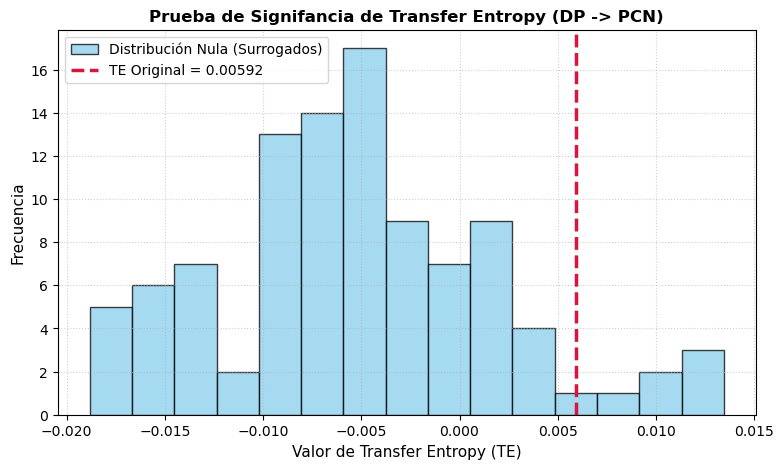

In [119]:
tau=65

DP = cessations["DP"].to_numpy()
PCN = cessations["PCN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(DP.astype(np.float64), PCN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (DP -> PCN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    DP_surrogate = circular_surrogate(DP)

    teCalc.initialise()
    teCalc.setObservations(DP_surrogate.astype(np.float64), PCN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (DP -> PCN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (PCN -> DP): 0.016040365770240372


Calculando surrogados: 100%|██████████| 100/100 [2:02:21<00:00, 73.41s/it] 


Distribución nula - Media: 0.01067, Std: 0.00358
Pseudo p-valor: 0.10891089108910891


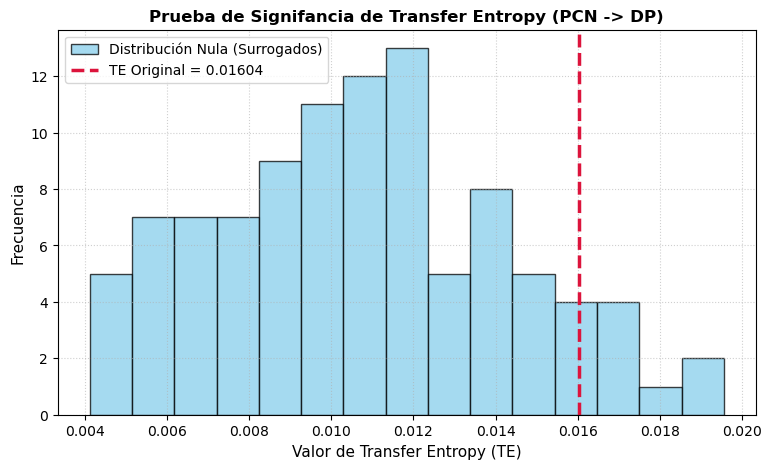

In [120]:
tau=50

PCN = cessations["PCN"].to_numpy()
DP = cessations["DP"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(PCN.astype(np.float64), DP.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (PCN -> DP): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    PCN_surrogate = circular_surrogate(PCN)

    teCalc.initialise()
    teCalc.setObservations(PCN_surrogate.astype(np.float64), DP.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (PCN -> DP)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

---

---

## RASPS

In [124]:
data3 = pd.read_csv("SGA_rasp.txt", sep=r"\s+", header=None)
rasps = data3.iloc[:, -4:].copy()
rasps.columns = ["VPd", "DP", "PCN", "CN"]

rasps.head()

,VPd,DP,PCN,CN
0,-65.0912,-63.635,-64.4749,-64.8126
1,-65.0843,-63.635,-64.4671,-64.8124
2,-65.0774,-63.635,-64.4594,-64.8122
3,-65.0704,-63.635,-64.4516,-64.8120
4,-65.0635,-63.635,-64.4438,-64.8118


In [125]:
DP = rasps["DP"].to_numpy()
CN = rasps["CN"].to_numpy()
VPd = rasps["VPd"].to_numpy()
PCN = rasps["PCN"].to_numpy()

Análisis de Tau: 100%|██████████| 100/100 [01:40<00:00,  1.00s/tau]


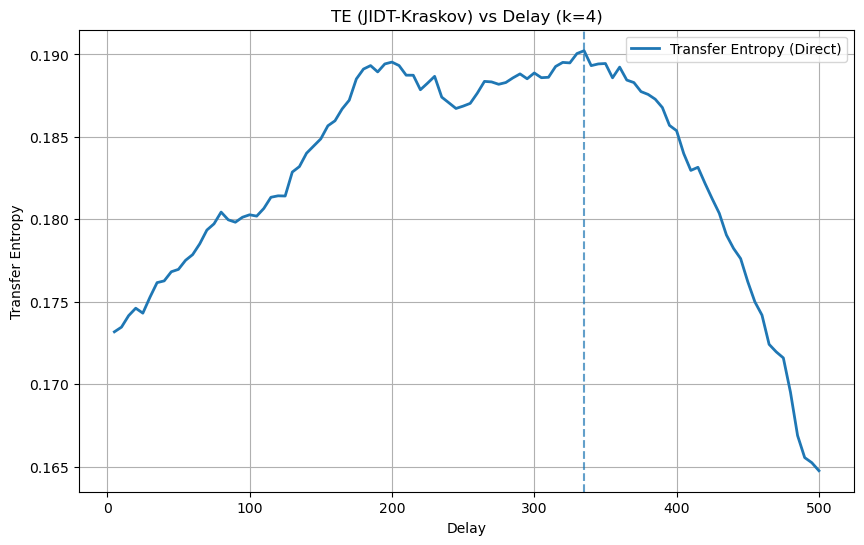

El delay óptimo para k=4 es: 335.000 ms


In [23]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(DP, CN, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [04:17<00:00,  2.58s/tau]


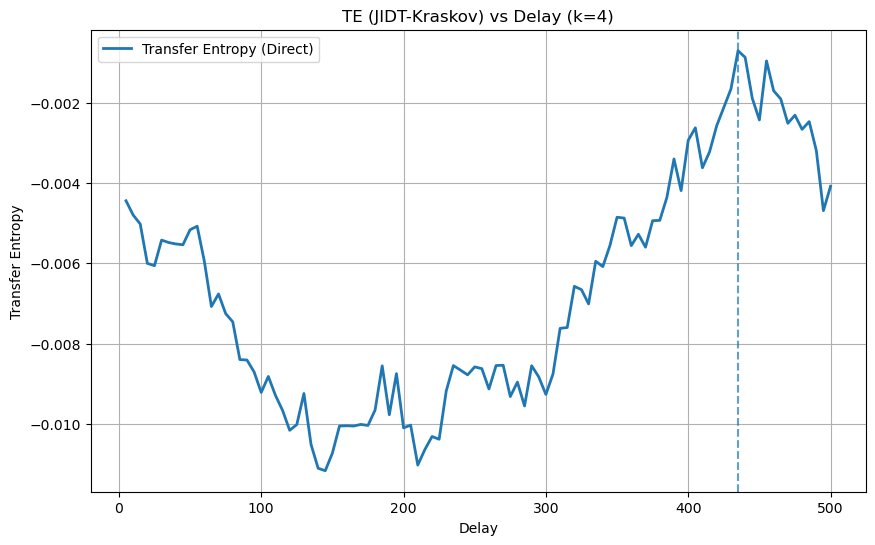

El delay óptimo para k=4 es: 435.000 ms


In [24]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(CN, DP, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [04:33<00:00,  2.74s/tau]


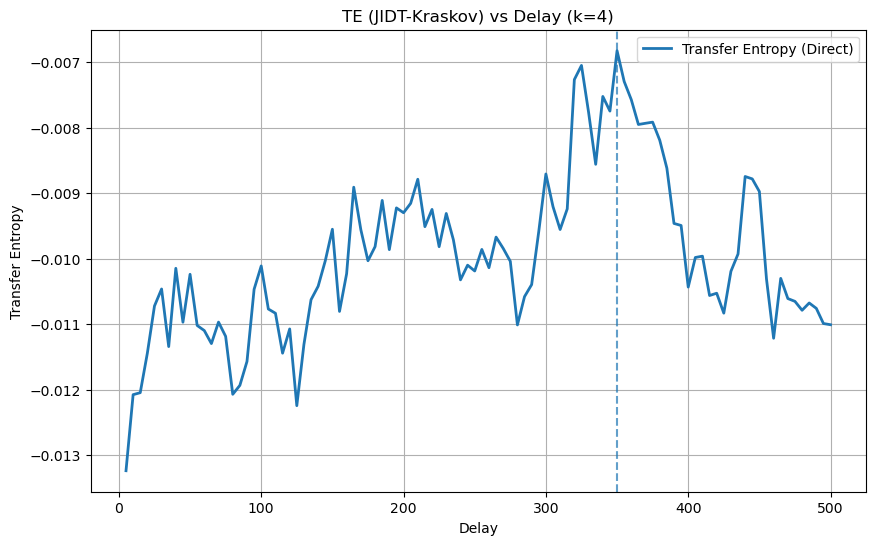

El delay óptimo para k=4 es: 350.000 ms


In [25]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(VPd, DP, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 300/300 [33:47<00:00,  6.76s/tau]


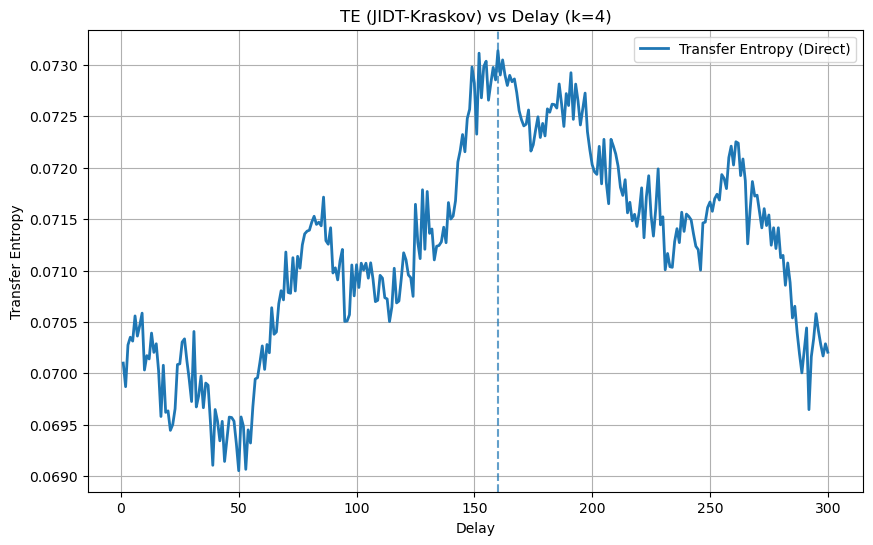

El delay óptimo para k=4 es: 160.000 ms


In [13]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(DP, VPd, n_vecinos=4, max_steps=300, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 300/300 [15:34<00:00,  3.11s/tau]


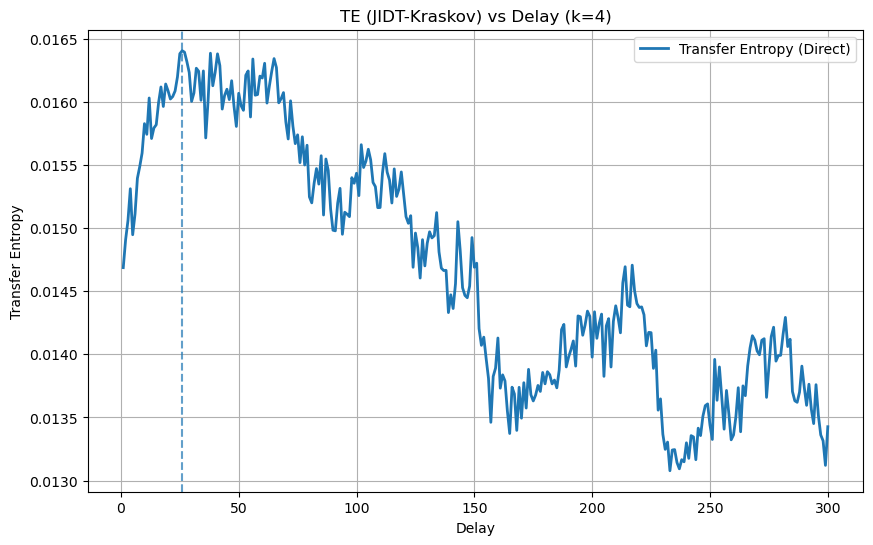

El delay óptimo para k=4 es: 26.000 ms


In [14]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(VPd, PCN, n_vecinos=4, max_steps=300, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [01:02<00:00,  1.60tau/s]


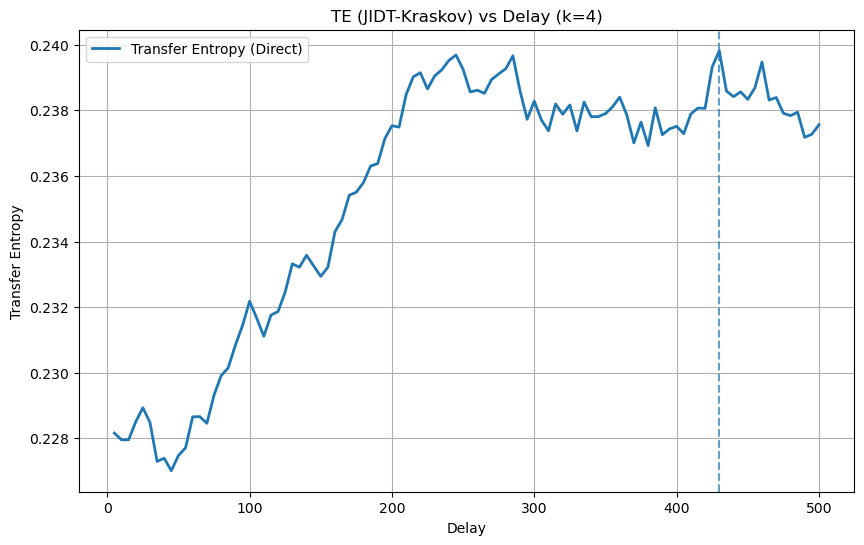

El delay óptimo para k=4 es: 430.000 ms


In [26]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(PCN, VPd, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [00:39<00:00,  2.54tau/s]


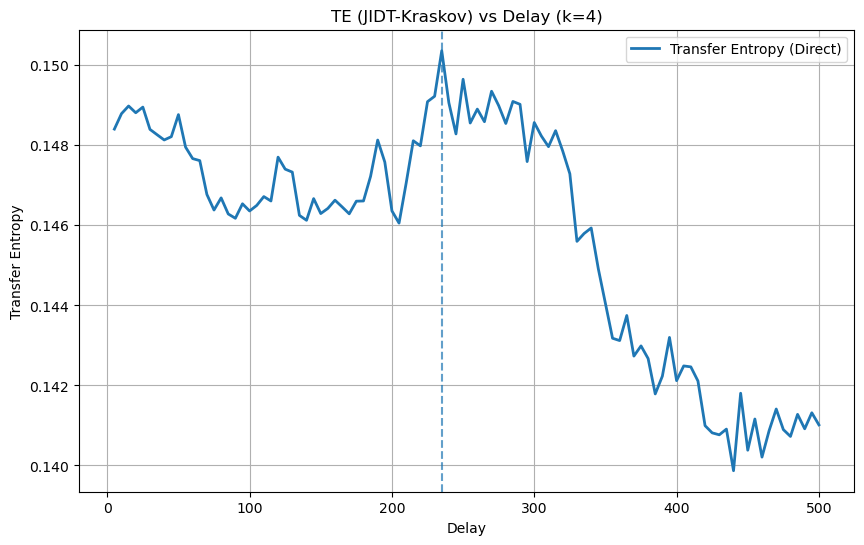

El delay óptimo para k=4 es: 235.000 ms


In [27]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(PCN, CN, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [00:55<00:00,  1.80tau/s]


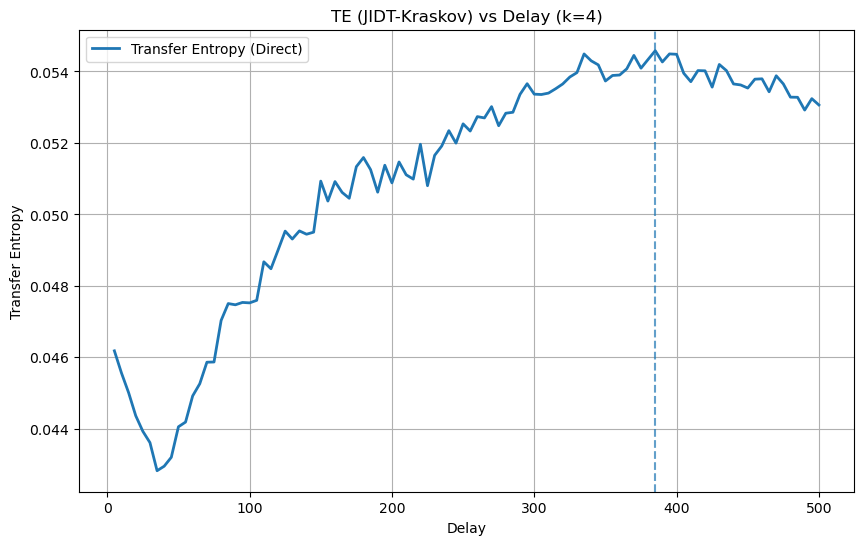

El delay óptimo para k=4 es: 385.000 ms


In [28]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(CN, PCN, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 600/600 [17:56<00:00,  1.79s/tau]


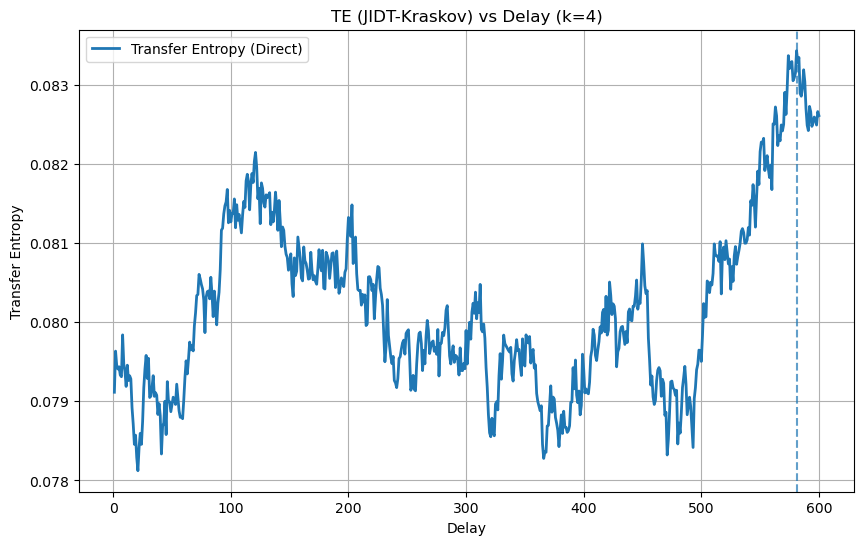

El delay óptimo para k=4 es: 581.000 ms


In [29]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(VPd, CN, n_vecinos=4, max_steps=600, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 500/500 [30:00<00:00,  3.60s/tau]


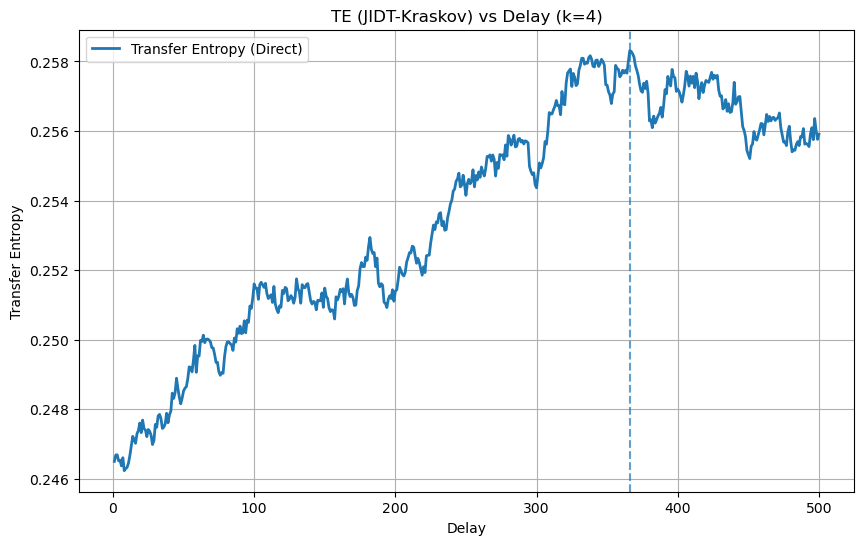

El delay óptimo para k=4 es: 366.000 ms


In [21]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(CN, VPd, n_vecinos=4, max_steps=500, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [01:55<00:00,  1.16s/tau]


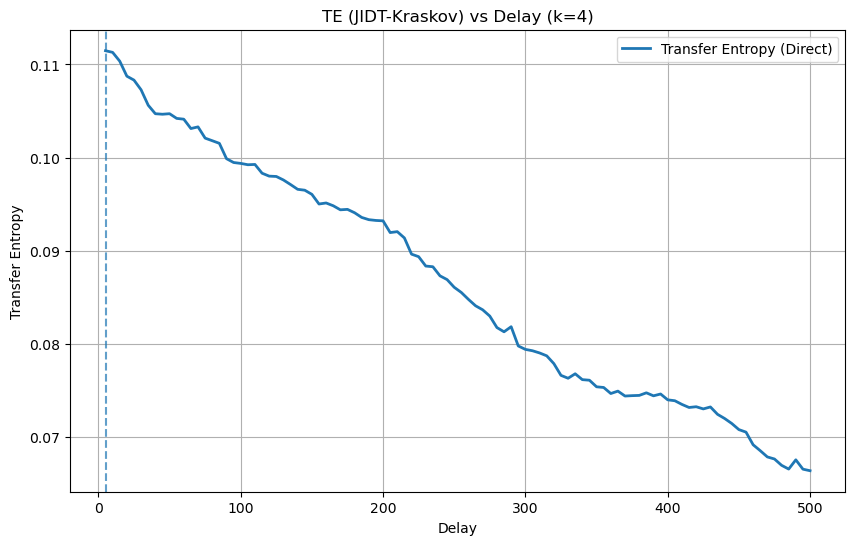

El delay óptimo para k=4 es: 5.000 ms


In [111]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(DP, PCN, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [04:35<00:00,  2.76s/tau]


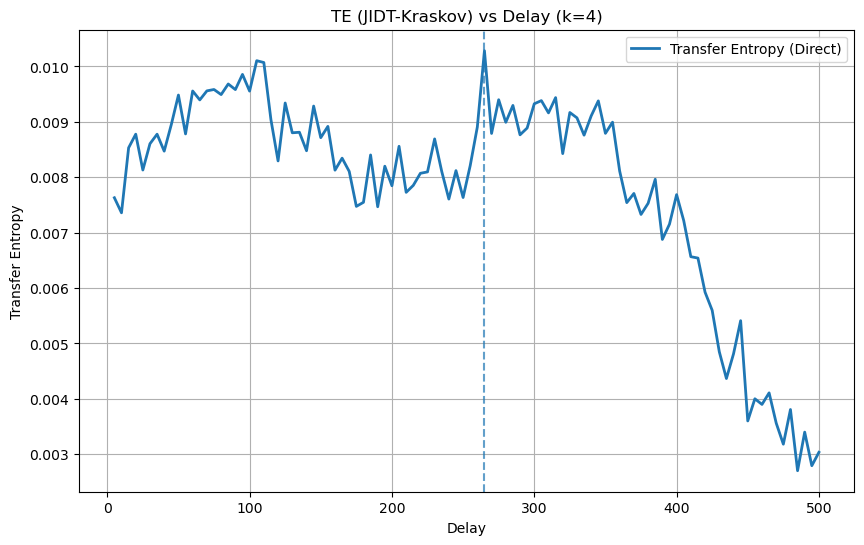

El delay óptimo para k=4 es: 265.000 ms


In [112]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(PCN, DP, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

---

---

TE Original (VPd -> VPd): -0.04240380018171086


Calculando surrogados: 100%|██████████| 100/100 [03:38<00:00,  2.19s/it]


Distribución nula - Media: 0.14871, Std: 0.05420
Pseudo p-valor: 1.0


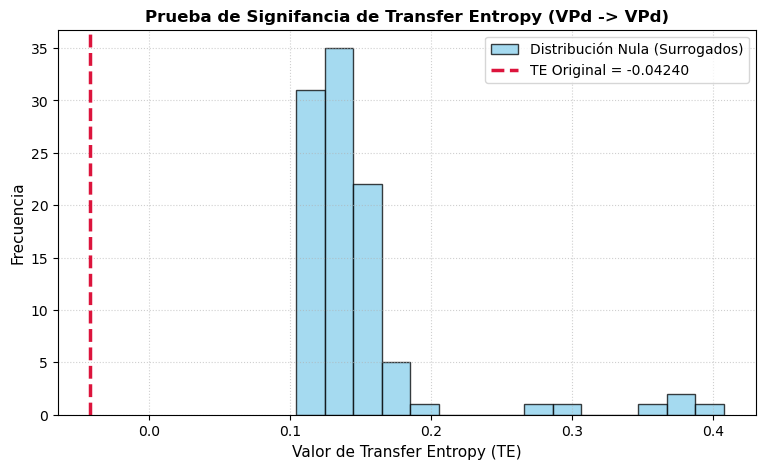

In [94]:
tau=1

VPd = rasps["VPd"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(VPd.astype(np.float64), VPd.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (VPd -> VPd): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    VPd_surrogate = circular_surrogate(VPd)

    teCalc.initialise()
    teCalc.setObservations(VPd_surrogate.astype(np.float64), VPd.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (VPd -> VPd)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (DP -> DP): -0.010535178916093235


Calculando surrogados: 100%|██████████| 100/100 [39:15<00:00, 23.55s/it]


Distribución nula - Media: 0.01322, Std: 0.01735
Pseudo p-valor: 0.9702970297029703


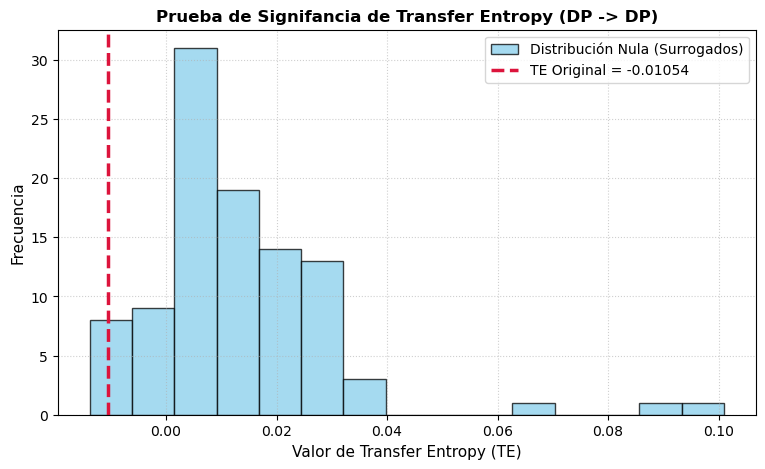

In [95]:
tau=1

DP = rasps["DP"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(DP.astype(np.float64), DP.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (DP -> DP): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    DP_surrogate = circular_surrogate(DP)

    teCalc.initialise()
    teCalc.setObservations(DP_surrogate.astype(np.float64), DP.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (DP -> DP)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (PCN -> PCN): -0.007347793656213186


Calculando surrogados: 100%|██████████| 100/100 [06:44<00:00,  4.04s/it]


Distribución nula - Media: 0.06104, Std: 0.02949
Pseudo p-valor: 1.0


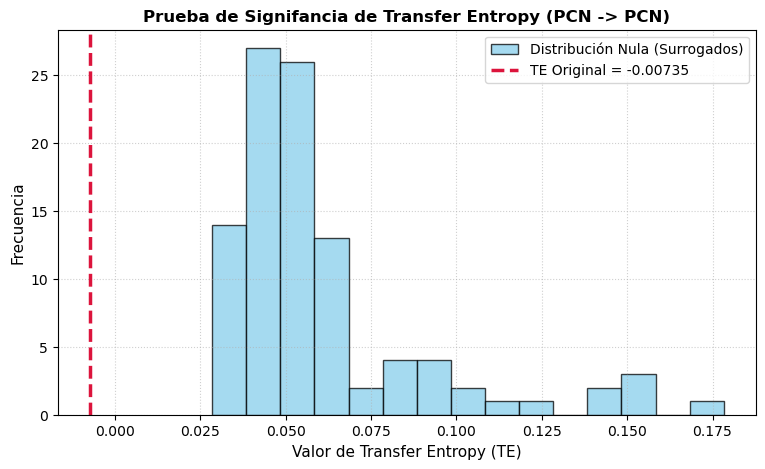

In [96]:
tau=1

PCN = rasps["PCN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(PCN.astype(np.float64), PCN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (PCN -> PCN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    PCN_surrogate = circular_surrogate(PCN)

    teCalc.initialise()
    teCalc.setObservations(PCN_surrogate.astype(np.float64), PCN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (PCN -> PCN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (CN -> CN): -0.016242353137583043


Calculando surrogados: 100%|██████████| 100/100 [03:47<00:00,  2.27s/it]


Distribución nula - Media: 0.15420, Std: 0.03473
Pseudo p-valor: 1.0


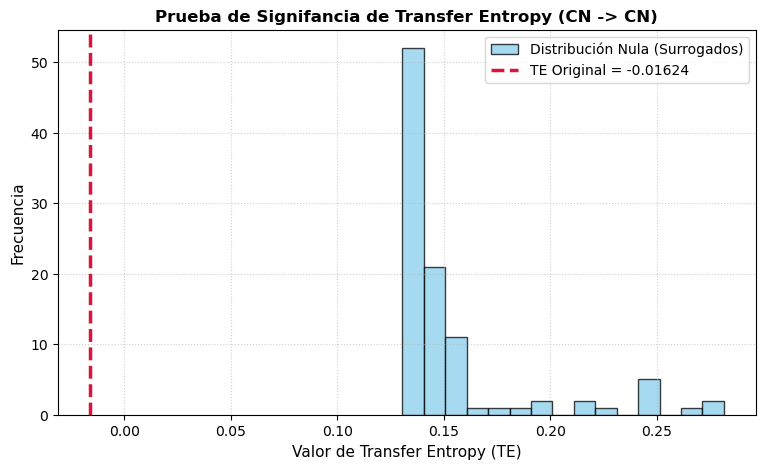

In [97]:
tau=1

CN = rasps["CN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(CN.astype(np.float64), CN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (CN -> CN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    CN_surrogate = circular_surrogate(CN)

    teCalc.initialise()
    teCalc.setObservations(CN_surrogate.astype(np.float64), CN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (CN -> CN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (VPd -> DP): -0.009625495701701237


Calculando surrogados: 100%|██████████| 100/100 [1:05:27<00:00, 39.27s/it]


Distribución nula - Media: -0.01051, Std: 0.00376
Pseudo p-valor: 0.31683168316831684


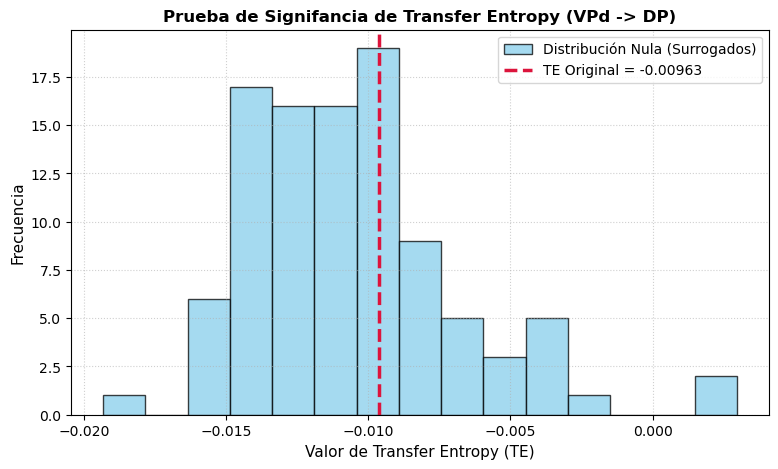

In [54]:
tau=350

VPd = rasps["VPd"].to_numpy()
DP = rasps["DP"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(VPd.astype(np.float64), DP.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (VPd -> DP): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    VPd_surrogate = circular_surrogate(VPd)

    teCalc.initialise()
    teCalc.setObservations(VPd_surrogate.astype(np.float64), DP.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (VPd -> DP)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (DP -> VPd): 0.0729507557101845


Calculando surrogados: 100%|██████████| 100/100 [11:51<00:00,  7.12s/it]


Distribución nula - Media: 0.06825, Std: 0.02439
Pseudo p-valor: 0.3564356435643564


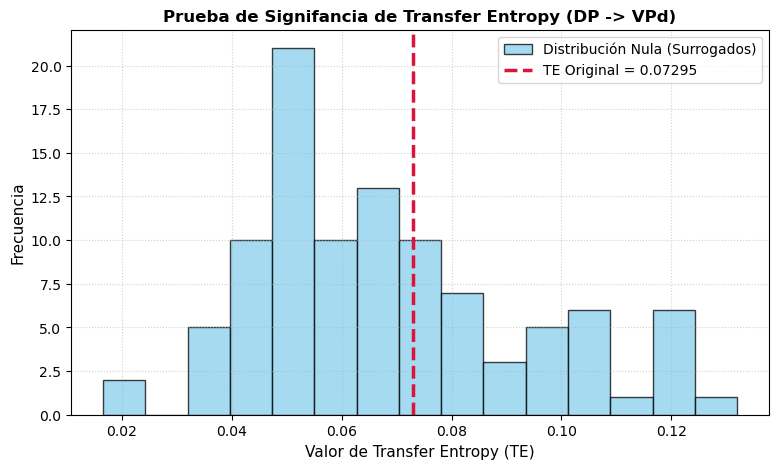

In [55]:
tau=160

DP = rasps["DP"].to_numpy()
VPd = rasps["VPd"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(DP.astype(np.float64), VPd.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (DP -> VPd): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    DP_surrogate = circular_surrogate(DP)

    teCalc.initialise()
    teCalc.setObservations(DP_surrogate.astype(np.float64), VPd.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (DP -> VPd)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (VPd -> PCN): 0.01637129614661914


Calculando surrogados: 100%|██████████| 100/100 [05:24<00:00,  3.24s/it]


Distribución nula - Media: 0.01766, Std: 0.00328
Pseudo p-valor: 0.6138613861386139


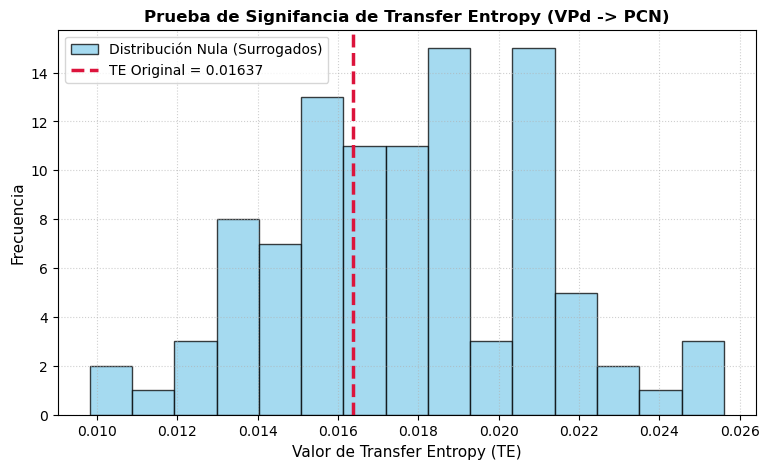

In [56]:
tau=26

VPd = rasps["VPd"].to_numpy()
PCN = rasps["PCN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(VPd.astype(np.float64), PCN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (VPd -> PCN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    VPd_surrogate = circular_surrogate(VPd)

    teCalc.initialise()
    teCalc.setObservations(VPd_surrogate.astype(np.float64), PCN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (VPd -> PCN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (PCN -> VPd): 0.23988965617800662


Calculando surrogados: 100%|██████████| 100/100 [03:16<00:00,  1.97s/it]


Distribución nula - Media: 0.24662, Std: 0.01341
Pseudo p-valor: 0.6831683168316832


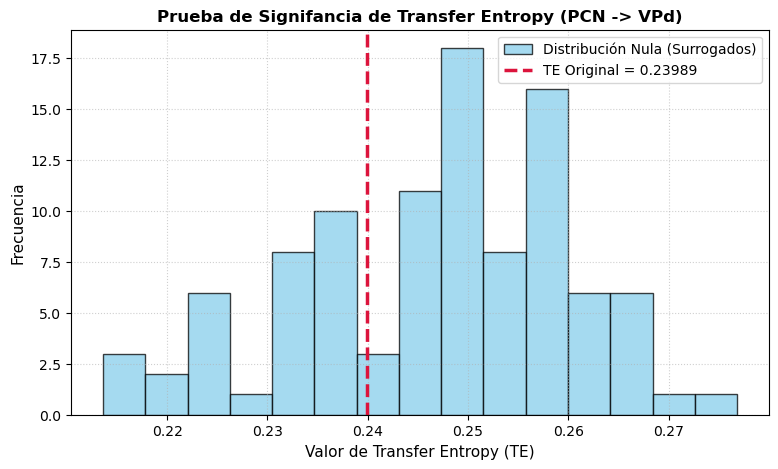

In [57]:
tau=430

PCN = rasps["PCN"].to_numpy()
VPd = rasps["VPd"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(PCN.astype(np.float64), VPd.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (PCN -> VPd): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    PCN_surrogate = circular_surrogate(PCN)

    teCalc.initialise()
    teCalc.setObservations(PCN_surrogate.astype(np.float64), VPd.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (PCN -> VPd)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (VPd -> CN): 0.08300364419685691


Calculando surrogados: 100%|██████████| 100/100 [03:00<00:00,  1.81s/it]


Distribución nula - Media: 0.08758, Std: 0.00458
Pseudo p-valor: 0.8118811881188119


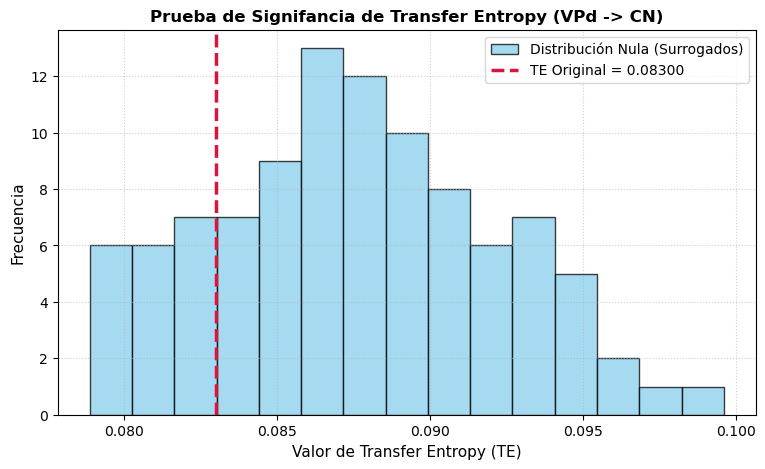

In [58]:
tau=581

VPd = rasps["VPd"].to_numpy()
CN = rasps["CN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(VPd.astype(np.float64), CN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (VPd -> CN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    VPd_surrogate = circular_surrogate(VPd)

    teCalc.initialise()
    teCalc.setObservations(VPd_surrogate.astype(np.float64), CN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (VPd -> CN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (CN -> VPd): 0.25827554488995075


Calculando surrogados: 100%|██████████| 100/100 [03:15<00:00,  1.95s/it]


Distribución nula - Media: 0.22003, Std: 0.01813
Pseudo p-valor: 0.06930693069306931


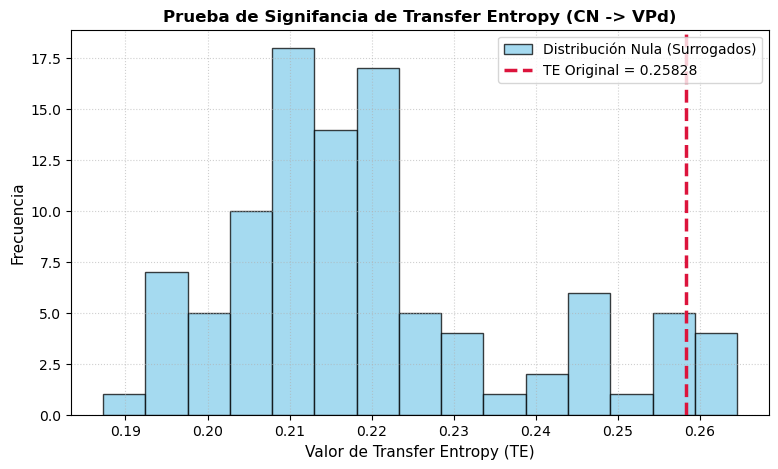

In [59]:
tau=366

CN = rasps["CN"].to_numpy()
VPd = rasps["VPd"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(CN.astype(np.float64), VPd.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (CN -> VPd): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    CN_surrogate = circular_surrogate(CN)

    teCalc.initialise()
    teCalc.setObservations(CN_surrogate.astype(np.float64), VPd.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (CN -> VPd)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (DP -> CN): 0.17554880456415933


Calculando surrogados: 100%|██████████| 100/100 [12:17<00:00,  7.38s/it]


Distribución nula - Media: 0.03938, Std: 0.03933
Pseudo p-valor: 0.019801980198019802


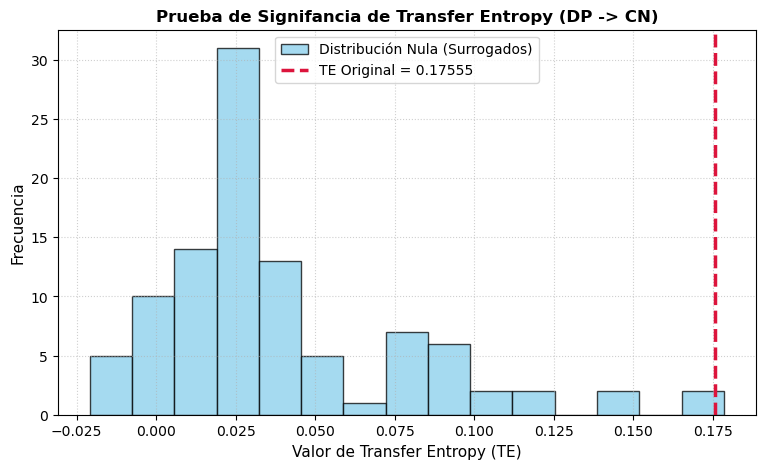

In [60]:
tau=335

DP = rasps["DP"].to_numpy()
CN = rasps["CN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(DP.astype(np.float64), CN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (DP -> CN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    DP_surrogate = circular_surrogate(DP)

    teCalc.initialise()
    teCalc.setObservations(DP_surrogate.astype(np.float64), CN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (DP -> CN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (CN -> DP): -0.0021654948330547263


Calculando surrogados: 100%|██████████| 100/100 [1:02:27<00:00, 37.48s/it]


Distribución nula - Media: 0.00868, Std: 0.00587
Pseudo p-valor: 0.9702970297029703


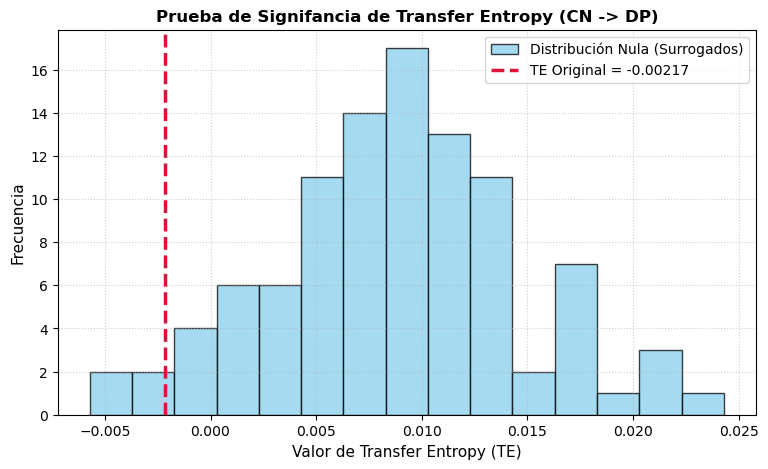

In [61]:
tau=435

CN = rasps["CN"].to_numpy()
DP = rasps["DP"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(CN.astype(np.float64), DP.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (CN -> DP): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    CN_surrogate = circular_surrogate(CN)

    teCalc.initialise()
    teCalc.setObservations(CN_surrogate.astype(np.float64), DP.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (CN -> DP)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (PCN -> CN): 0.14729370684565346


Calculando surrogados: 100%|██████████| 100/100 [04:09<00:00,  2.49s/it]


Distribución nula - Media: 0.14856, Std: 0.00865
Pseudo p-valor: 0.4752475247524752


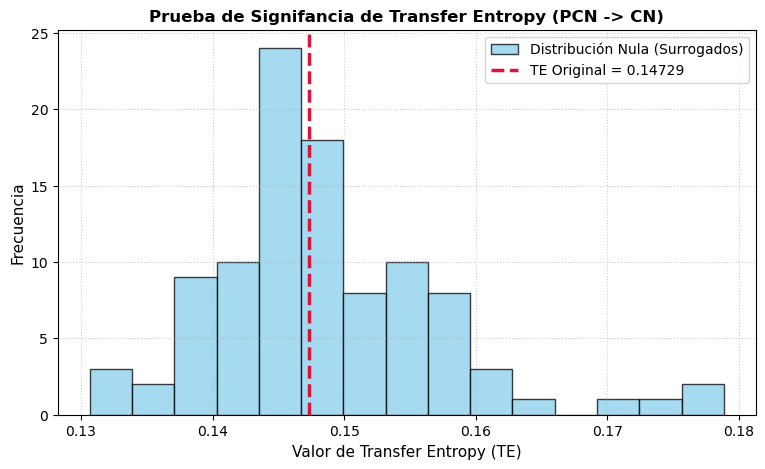

In [62]:
tau=235

PCN = rasps["PCN"].to_numpy()
CN = rasps["CN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(PCN.astype(np.float64), CN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (PCN -> CN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    PCN_surrogate = circular_surrogate(PCN)

    teCalc.initialise()
    teCalc.setObservations(PCN_surrogate.astype(np.float64), CN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (PCN -> CN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (CN -> PCN): 0.06546366680778526


Calculando surrogados: 100%|██████████| 100/100 [05:57<00:00,  3.57s/it]


Distribución nula - Media: 0.04530, Std: 0.01459
Pseudo p-valor: 0.039603960396039604


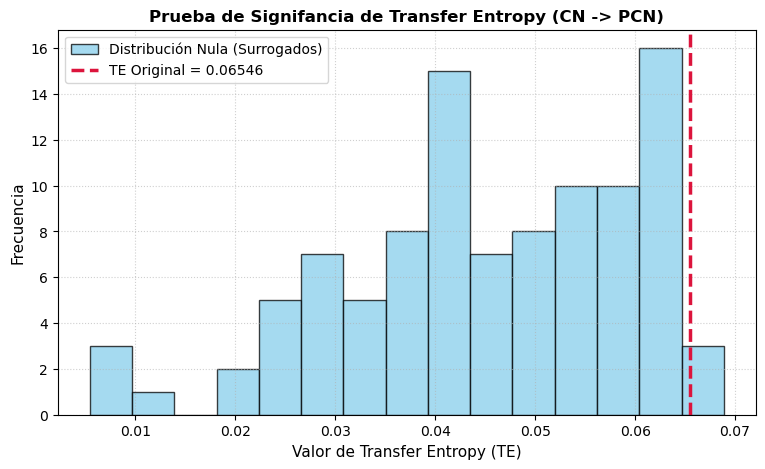

In [63]:
tau=385

CN = rasps["CN"].to_numpy()
PCN = rasps["PCN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(CN.astype(np.float64), PCN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (CN -> PCN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    CN_surrogate = circular_surrogate(CN)

    teCalc.initialise()
    teCalc.setObservations(CN_surrogate.astype(np.float64), PCN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (CN -> PCN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (DP -> PCN): 0.09645932716170136


Calculando surrogados: 100%|██████████| 100/100 [16:20<00:00,  9.81s/it]


Distribución nula - Media: 0.01868, Std: 0.02527
Pseudo p-valor: 0.009900990099009901


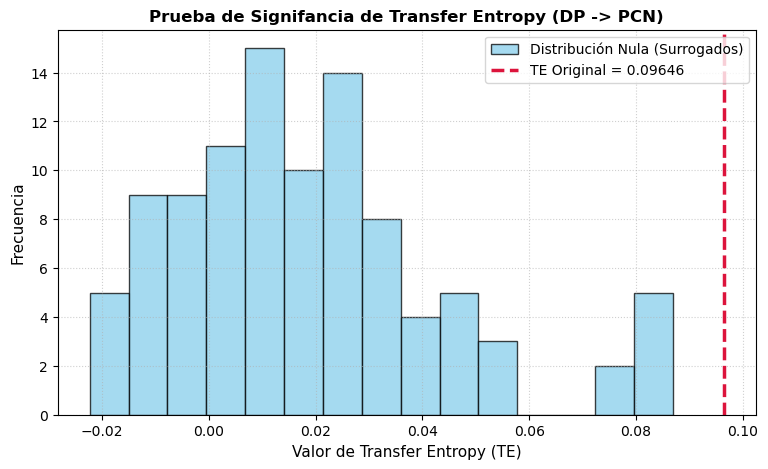

In [123]:
tau=5

DP = rasps["DP"].to_numpy()
PCN = rasps["PCN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(DP.astype(np.float64), PCN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (DP -> PCN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    DP_surrogate = circular_surrogate(DP)

    teCalc.initialise()
    teCalc.setObservations(DP_surrogate.astype(np.float64), PCN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (DP -> PCN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (PCN -> DP): 0.0033909405224099576


Calculando surrogados: 100%|██████████| 100/100 [1:49:40<00:00, 65.81s/it]


Distribución nula - Media: 0.01773, Std: 0.00714
Pseudo p-valor: 0.9801980198019802


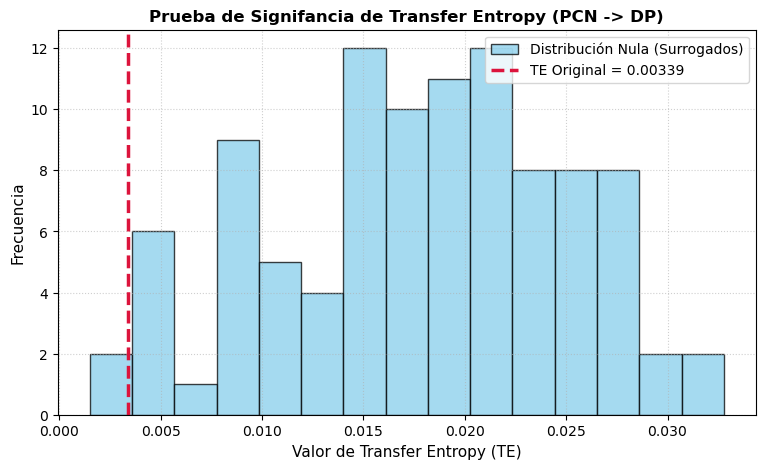

In [126]:
tau=265

PCN = rasps["PCN"].to_numpy()
DP = rasps["DP"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(PCN.astype(np.float64), DP.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (PCN -> DP): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    PCN_surrogate = circular_surrogate(PCN)

    teCalc.initialise()
    teCalc.setObservations(PCN_surrogate.astype(np.float64), DP.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (PCN -> DP)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

---

---

## SCALLOPS

In [127]:
data4 = pd.read_csv("SGA_sca.txt", sep=r"\s+", header=None)
scallops = data4.iloc[:, -4:].copy()
scallops.columns = ["VPd", "DP", "PCN", "CN"]

scallops.head()

,VPd,DP,PCN,CN
0,-65.0912,-63.635,-64.4749,-64.8126
1,-65.0843,-63.635,-64.4671,-64.8124
2,-65.0774,-63.635,-64.4594,-64.8122
3,-65.0704,-63.635,-64.4516,-64.8120
4,-65.0635,-63.635,-64.4438,-64.8118


In [128]:
DP = scallops["DP"].to_numpy()
CN = scallops["CN"].to_numpy()
VPd = scallops["VPd"].to_numpy()
PCN = scallops["PCN"].to_numpy()

Análisis de Tau: 100%|██████████| 100/100 [01:34<00:00,  1.05tau/s]


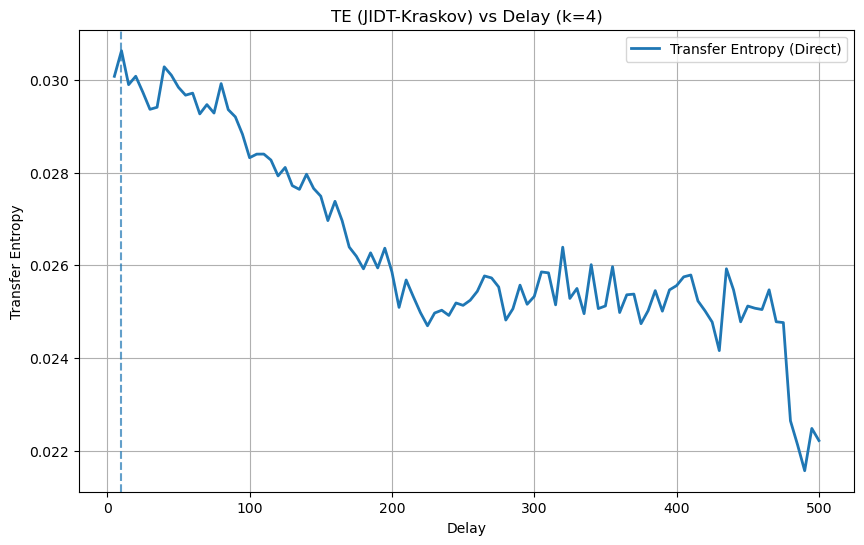

El delay óptimo para k=4 es: 10.000 ms


In [31]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(DP, CN, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [05:24<00:00,  3.24s/tau]


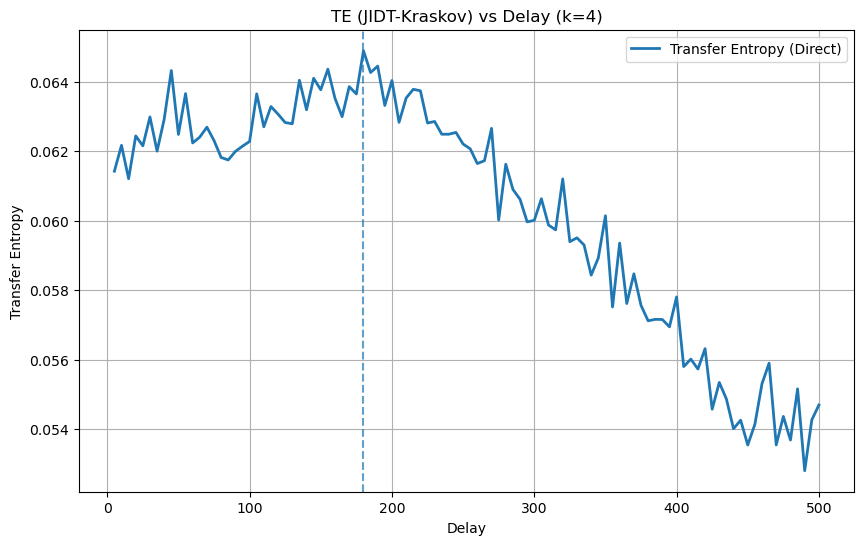

El delay óptimo para k=4 es: 180.000 ms


In [34]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(CN, DP, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 300/300 [23:28:40<00:00, 281.73s/tau]      


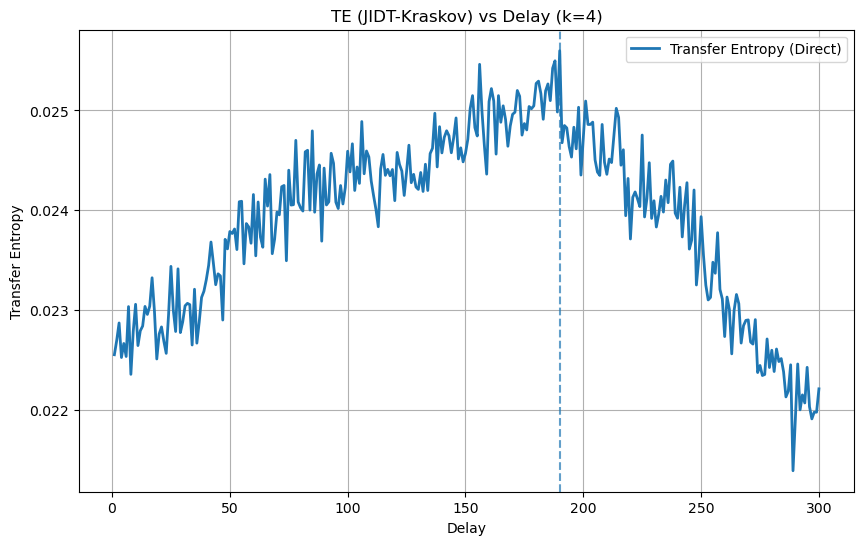

El delay óptimo para k=4 es: 190.000 ms


In [36]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(VPd, DP, n_vecinos=4, max_steps=300, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 300/300 [47:11<00:00,  9.44s/tau]


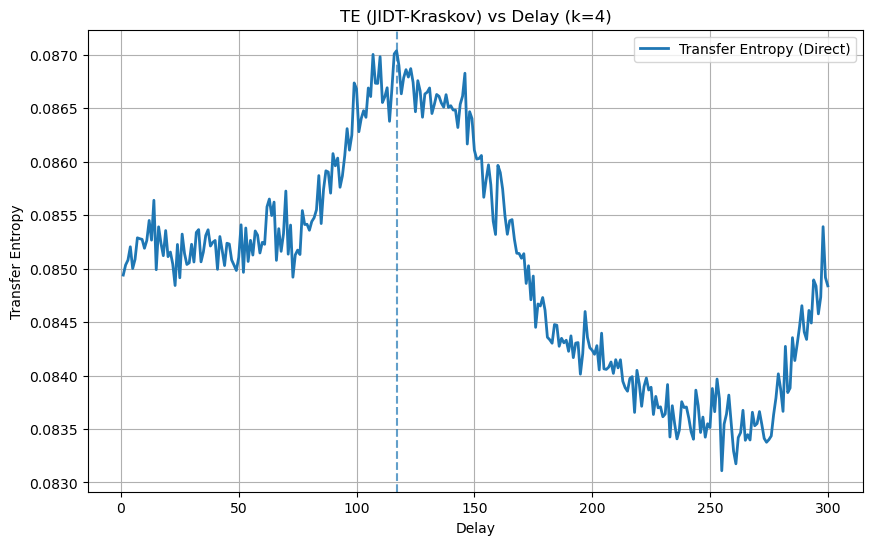

El delay óptimo para k=4 es: 117.000 ms


In [37]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(DP, VPd, n_vecinos=4, max_steps=300, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 300/300 [23:29<00:00,  4.70s/tau]


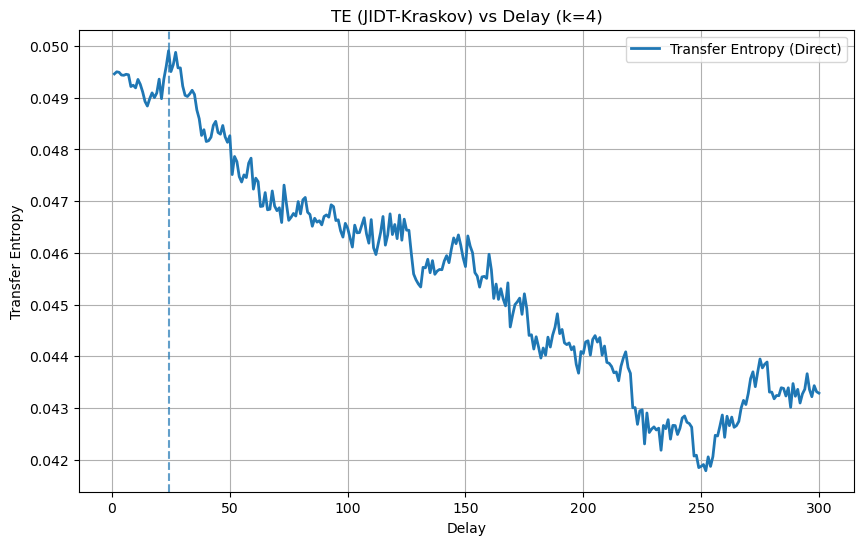

El delay óptimo para k=4 es: 24.000 ms


In [38]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(VPd, PCN, n_vecinos=4, max_steps=300, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [00:31<00:00,  3.19tau/s]


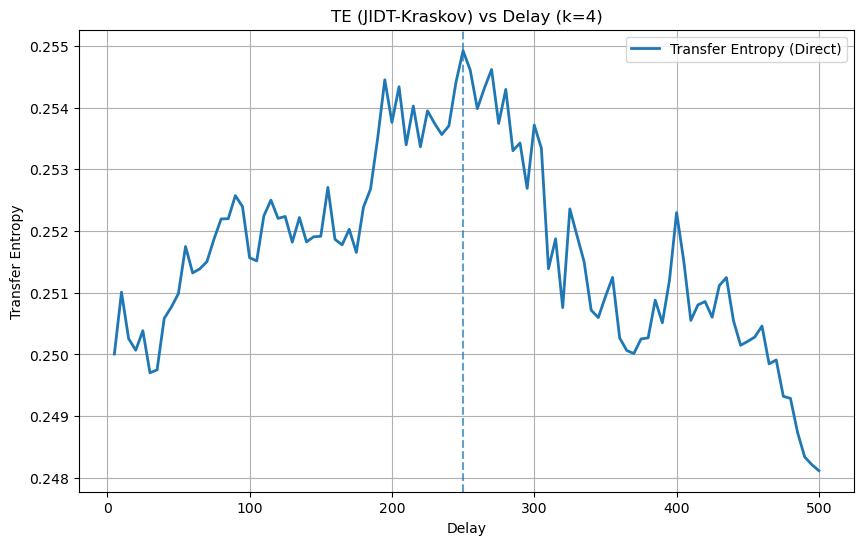

El delay óptimo para k=4 es: 250.000 ms


In [32]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(PCN, VPd, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 300/300 [38:07<00:00,  7.62s/tau]


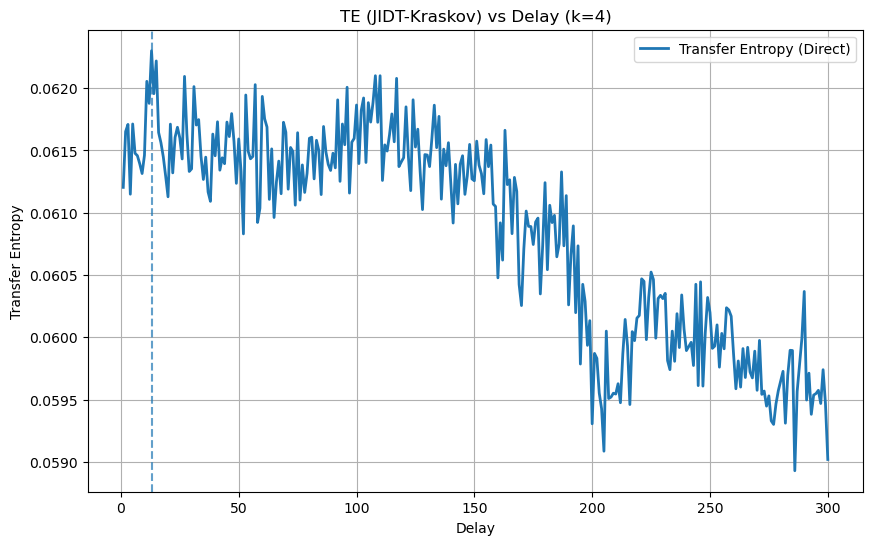

El delay óptimo para k=4 es: 13.000 ms


In [40]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(PCN, CN, n_vecinos=4, max_steps=300, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 300/300 [28:23<00:00,  5.68s/tau]


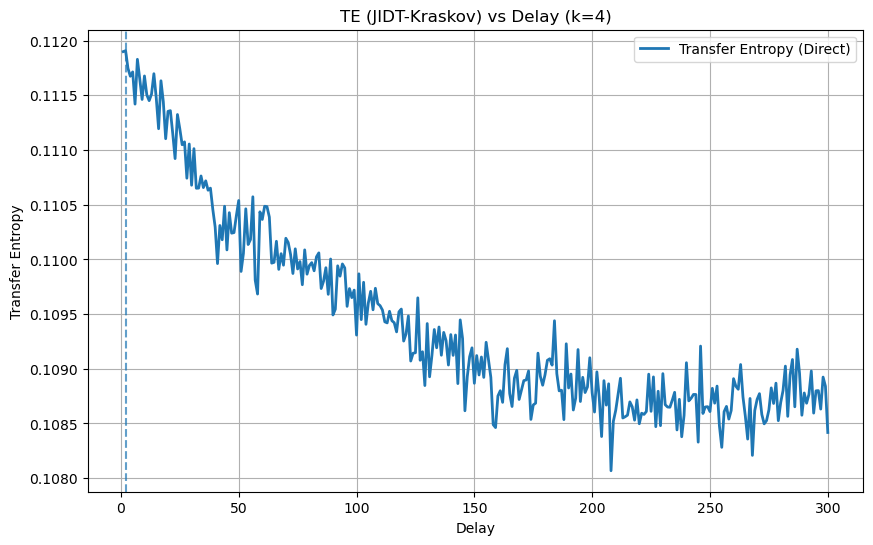

El delay óptimo para k=4 es: 2.000 ms


In [41]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(CN, PCN, n_vecinos=4, max_steps=300, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 600/600 [27:49<00:00,  2.78s/tau]


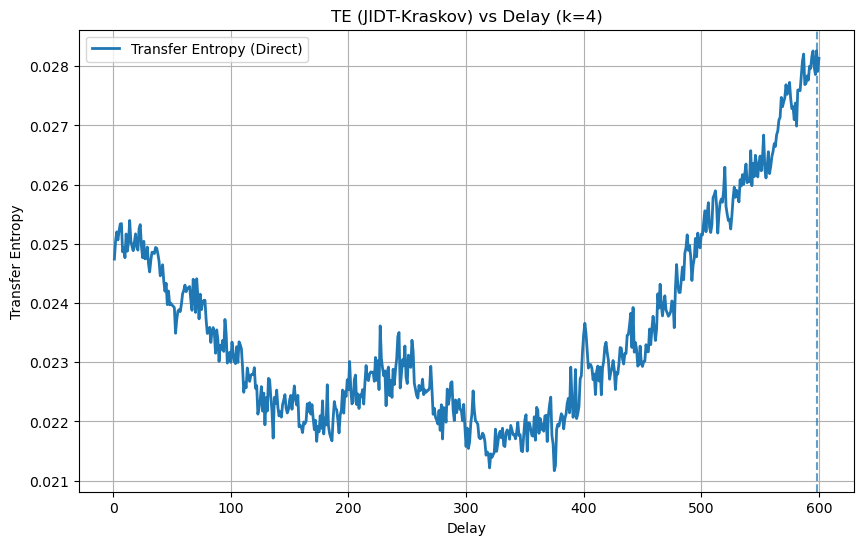

El delay óptimo para k=4 es: 598.000 ms


In [32]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(VPd, CN, n_vecinos=4, max_steps=600, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [00:39<00:00,  2.53tau/s]


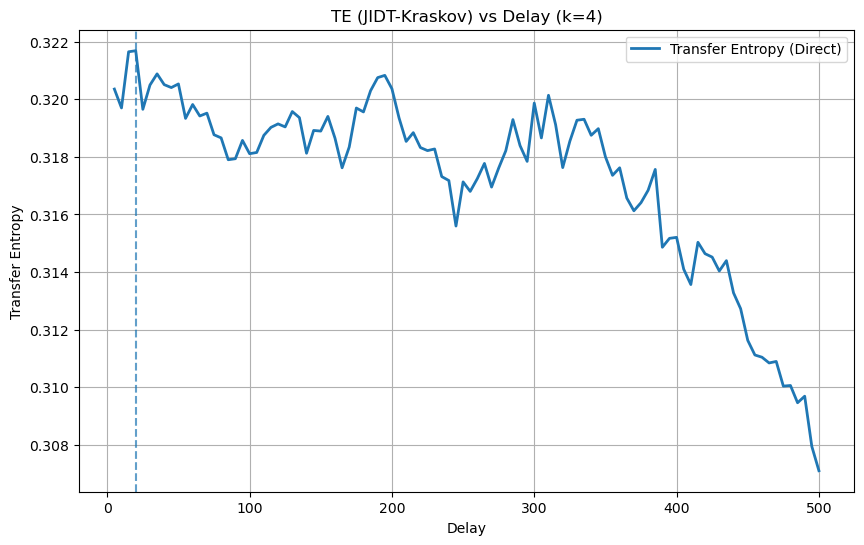

El delay óptimo para k=4 es: 20.000 ms


In [33]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(CN, VPd, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [01:51<00:00,  1.12s/tau]


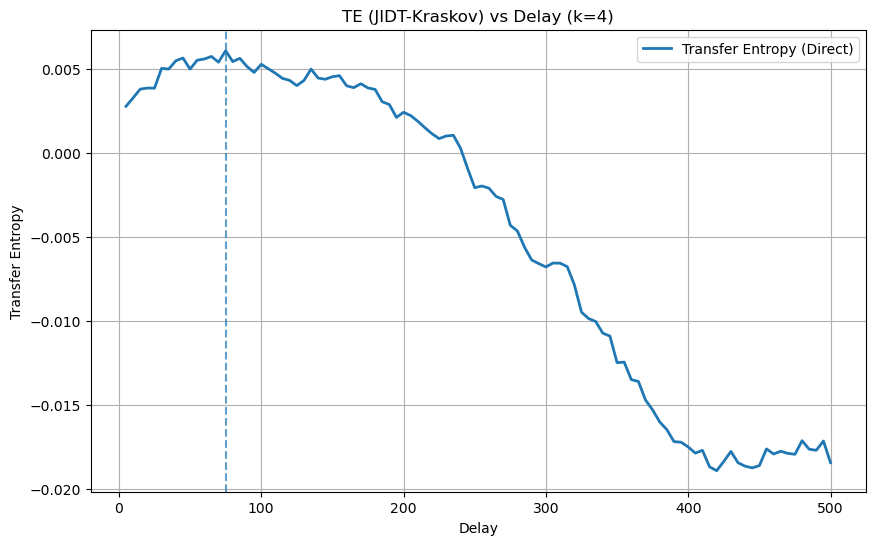

El delay óptimo para k=4 es: 75.000 ms


In [115]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(DP, PCN, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 100/100 [05:59<00:00,  3.59s/tau]


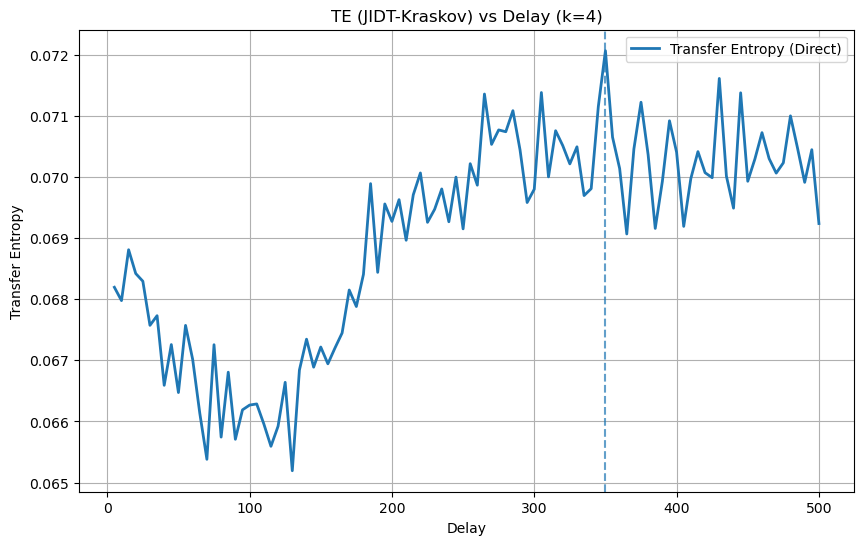

El delay óptimo para k=4 es: 350.000 ms


In [116]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(PCN, DP, n_vecinos=4, max_steps=100, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= True, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

---

---

TE Original (VPd -> VPd): -0.044864912760280484


Calculando surrogados: 100%|██████████| 100/100 [02:38<00:00,  1.59s/it]


Distribución nula - Media: 0.12881, Std: 0.02791
Pseudo p-valor: 1.0


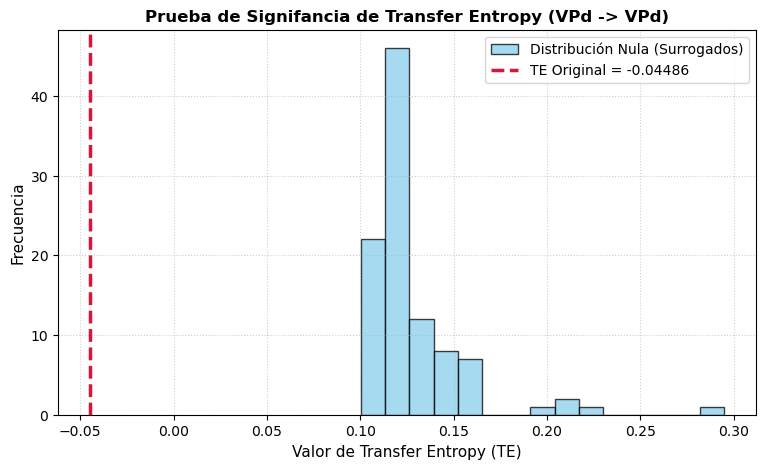

In [100]:
tau=1

VPd = scallops["VPd"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(VPd.astype(np.float64), VPd.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (VPd -> VPd): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    VPd_surrogate = circular_surrogate(VPd)

    teCalc.initialise()
    teCalc.setObservations(VPd_surrogate.astype(np.float64), VPd.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (VPd -> VPd)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (DP -> DP): -0.00459884214514239


Calculando surrogados: 100%|██████████| 100/100 [25:20<00:00, 15.21s/it]


Distribución nula - Media: 0.00439, Std: 0.00771
Pseudo p-valor: 0.9900990099009901


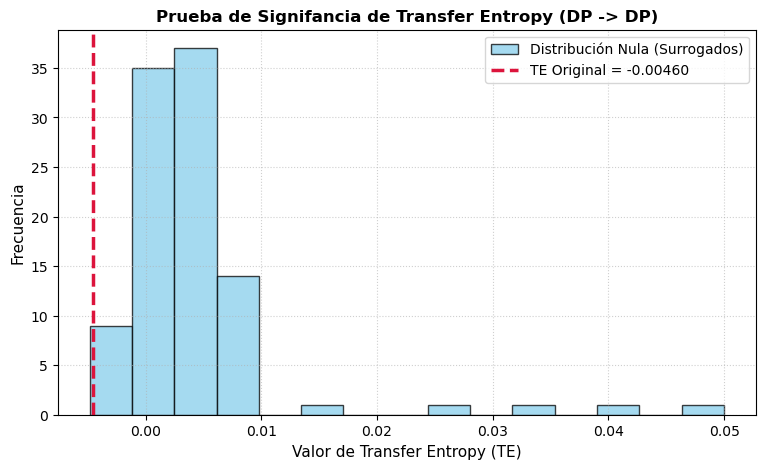

In [101]:
tau=1

DP = scallops["DP"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(DP.astype(np.float64), DP.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (DP -> DP): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    DP_surrogate = circular_surrogate(DP)

    teCalc.initialise()
    teCalc.setObservations(DP_surrogate.astype(np.float64), DP.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (DP -> DP)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (PCN -> PCN): -0.010579305374358361


Calculando surrogados: 100%|██████████| 100/100 [05:32<00:00,  3.33s/it]


Distribución nula - Media: 0.07944, Std: 0.02961
Pseudo p-valor: 1.0


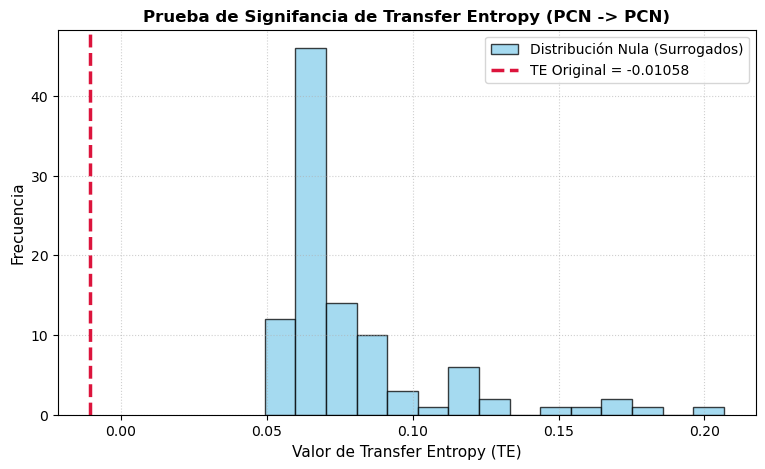

In [102]:
tau=1

PCN = scallops["PCN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(PCN.astype(np.float64), PCN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (PCN -> PCN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    PCN_surrogate = circular_surrogate(PCN)

    teCalc.initialise()
    teCalc.setObservations(PCN_surrogate.astype(np.float64), PCN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (PCN -> PCN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (CN -> CN): -0.0036816866713453855


Calculando surrogados: 100%|██████████| 100/100 [06:40<00:00,  4.01s/it]


Distribución nula - Media: 0.06964, Std: 0.02867
Pseudo p-valor: 1.0


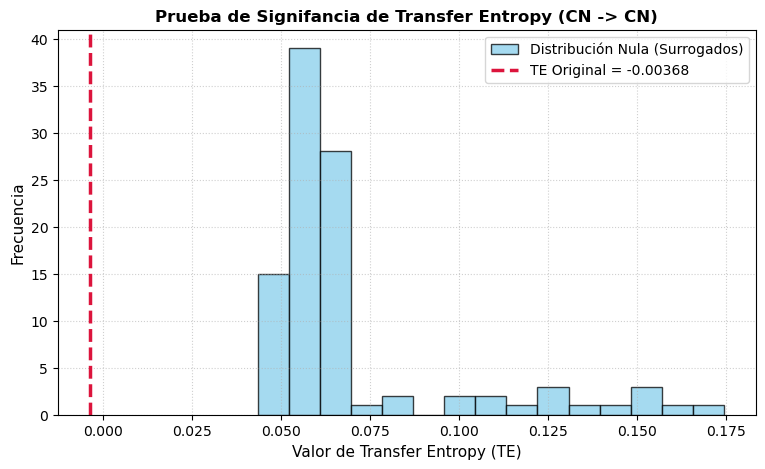

In [103]:
tau=1

CN = scallops["CN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(CN.astype(np.float64), CN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (CN -> CN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    CN_surrogate = circular_surrogate(CN)

    teCalc.initialise()
    teCalc.setObservations(CN_surrogate.astype(np.float64), CN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (CN -> CN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (VPd -> DP): 0.025293541170862577


Calculando surrogados: 100%|██████████| 100/100 [2:46:10<00:00, 99.70s/it]  


Distribución nula - Media: 0.01895, Std: 0.00349
Pseudo p-valor: 0.1188118811881188


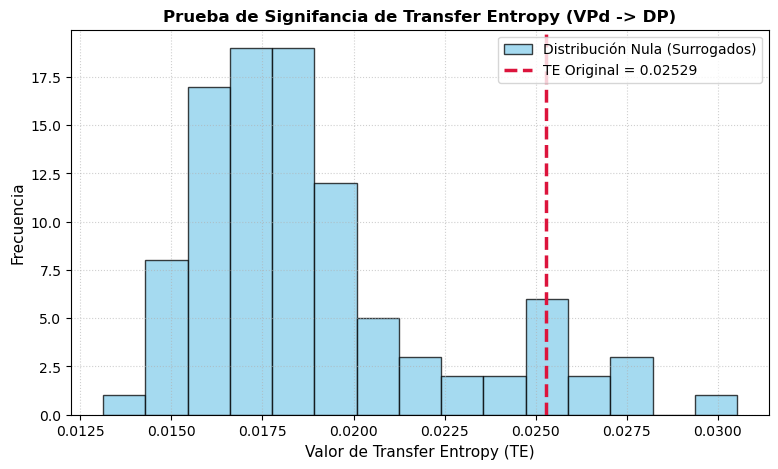

In [66]:
tau=190

VPd = scallops["VPd"].to_numpy()
DP = scallops["DP"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(VPd.astype(np.float64), DP.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (VPd -> DP): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    VPd_surrogate = circular_surrogate(VPd)

    teCalc.initialise()
    teCalc.setObservations(VPd_surrogate.astype(np.float64), DP.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (VPd -> DP)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (DP -> VPd): 0.08711424341779184


Calculando surrogados: 100%|██████████| 100/100 [22:43<00:00, 13.64s/it]


Distribución nula - Media: 0.05117, Std: 0.03654
Pseudo p-valor: 0.1485148514851485


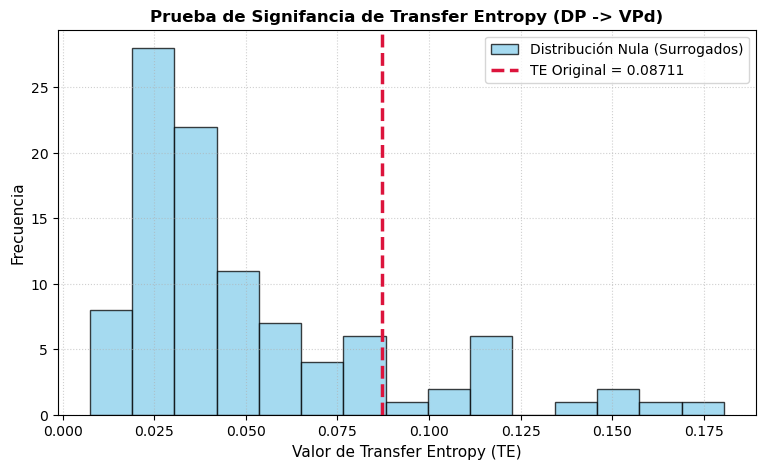

In [67]:
tau=117

DP = scallops["DP"].to_numpy()
VPd = scallops["VPd"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(DP.astype(np.float64), VPd.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (DP -> VPd): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    DP_surrogate = circular_surrogate(DP)

    teCalc.initialise()
    teCalc.setObservations(DP_surrogate.astype(np.float64), VPd.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (DP -> VPd)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (VPd -> PCN): 0.04943304533598192


Calculando surrogados: 100%|██████████| 100/100 [04:17<00:00,  2.57s/it]


Distribución nula - Media: 0.04515, Std: 0.00424
Pseudo p-valor: 0.16831683168316833


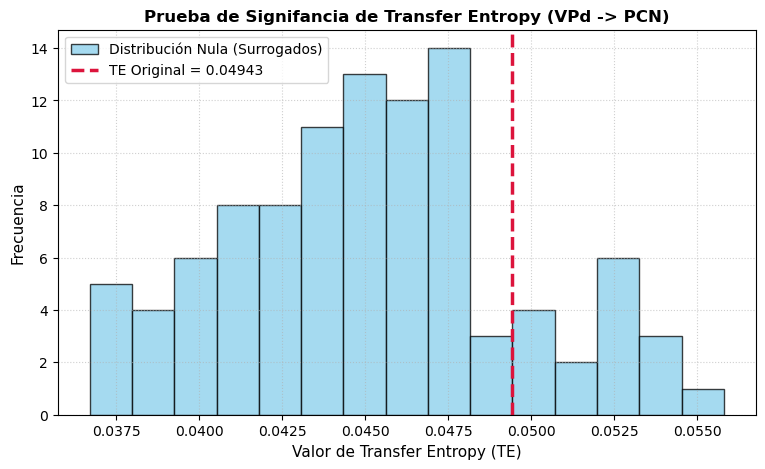

In [68]:
tau=24

VPd = scallops["VPd"].to_numpy()
PCN = scallops["PCN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(VPd.astype(np.float64), PCN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (VPd -> PCN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    VPd_surrogate = circular_surrogate(VPd)

    teCalc.initialise()
    teCalc.setObservations(VPd_surrogate.astype(np.float64), PCN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (VPd -> PCN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (PCN -> VPd): 0.21611658520690735


Calculando surrogados: 100%|██████████| 100/100 [02:36<00:00,  1.56s/it]


Distribución nula - Media: 0.20876, Std: 0.01892
Pseudo p-valor: 0.26732673267326734


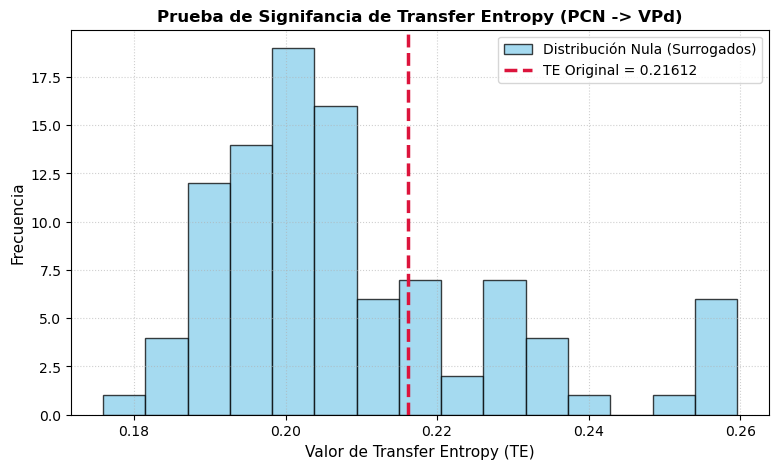

In [69]:
tau=250

PCN = scallops["PCN"].to_numpy()
VPd = scallops["VPd"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(PCN.astype(np.float64), VPd.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (PCN -> VPd): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    PCN_surrogate = circular_surrogate(PCN)

    teCalc.initialise()
    teCalc.setObservations(PCN_surrogate.astype(np.float64), VPd.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (PCN -> VPd)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (VPd -> CN): 0.028121146211298464


Calculando surrogados: 100%|██████████| 100/100 [05:18<00:00,  3.18s/it]


Distribución nula - Media: 0.03706, Std: 0.00348
Pseudo p-valor: 0.9900990099009901


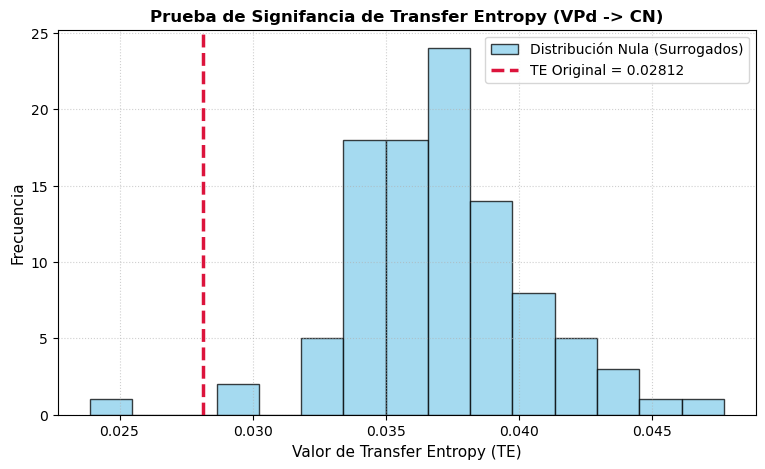

In [70]:
tau=598

VPd = scallops["VPd"].to_numpy()
CN = scallops["CN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(VPd.astype(np.float64), CN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (VPd -> CN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    VPd_surrogate = circular_surrogate(VPd)

    teCalc.initialise()
    teCalc.setObservations(VPd_surrogate.astype(np.float64), CN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (VPd -> CN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (CN -> VPd): 0.27375159515409164


Calculando surrogados: 100%|██████████| 100/100 [02:40<00:00,  1.60s/it]


Distribución nula - Media: 0.22988, Std: 0.02867
Pseudo p-valor: 0.1485148514851485


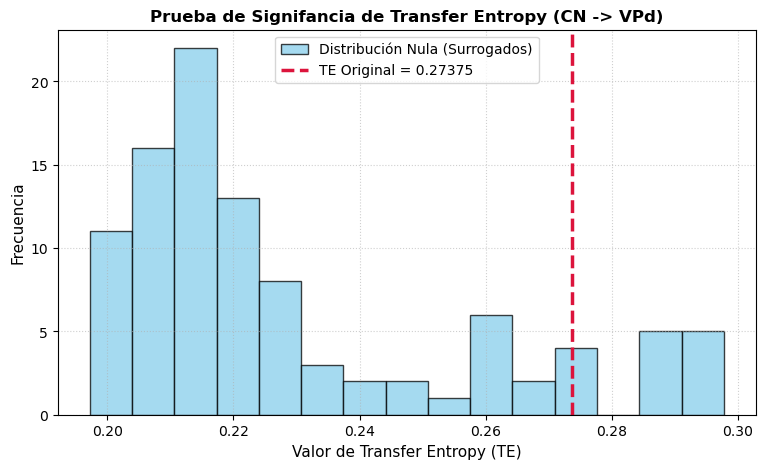

In [71]:
tau=20

CN = scallops["CN"].to_numpy()
VPd = scallops["VPd"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(CN.astype(np.float64), VPd.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (CN -> VPd): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    CN_surrogate = circular_surrogate(CN)

    teCalc.initialise()
    teCalc.setObservations(CN_surrogate.astype(np.float64), VPd.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (CN -> VPd)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (DP -> CN): 0.021338828457115655


Calculando surrogados: 100%|██████████| 100/100 [20:11<00:00, 12.12s/it]


Distribución nula - Media: -0.01040, Std: 0.01140
Pseudo p-valor: 0.0297029702970297


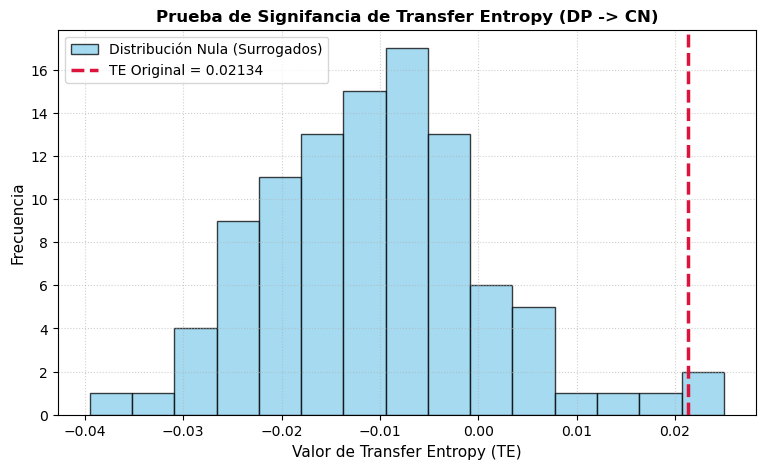

In [72]:
tau=10

DP = scallops["DP"].to_numpy()
CN = scallops["CN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(DP.astype(np.float64), CN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (DP -> CN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    DP_surrogate = circular_surrogate(DP)

    teCalc.initialise()
    teCalc.setObservations(DP_surrogate.astype(np.float64), CN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (DP -> CN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (CN -> DP): 0.04087483468698272


Calculando surrogados: 100%|██████████| 100/100 [2:46:58<00:00, 100.19s/it] 


Distribución nula - Media: 0.01620, Std: 0.00603
Pseudo p-valor: 0.019801980198019802


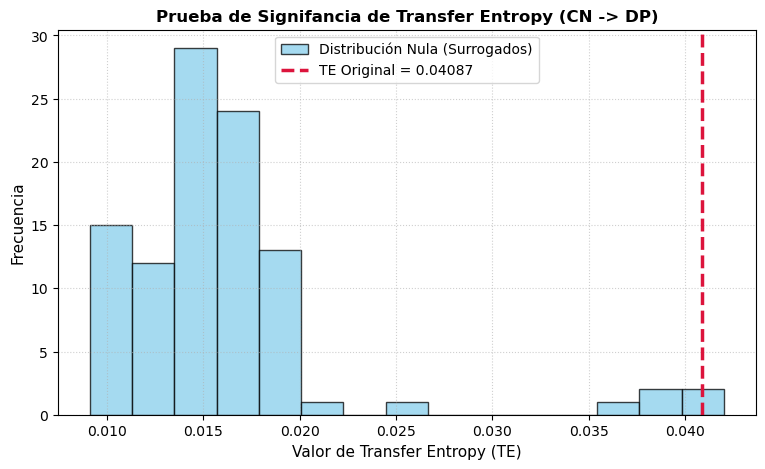

In [73]:
tau=180

CN = scallops["CN"].to_numpy()
DP = scallops["DP"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(CN.astype(np.float64), DP.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (CN -> DP): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    CN_surrogate = circular_surrogate(CN)

    teCalc.initialise()
    teCalc.setObservations(CN_surrogate.astype(np.float64), DP.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (CN -> DP)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (PCN -> CN): 0.06134157527430406


Calculando surrogados: 100%|██████████| 100/100 [08:05<00:00,  4.85s/it]


Distribución nula - Media: 0.05672, Std: 0.01219
Pseudo p-valor: 0.18811881188118812


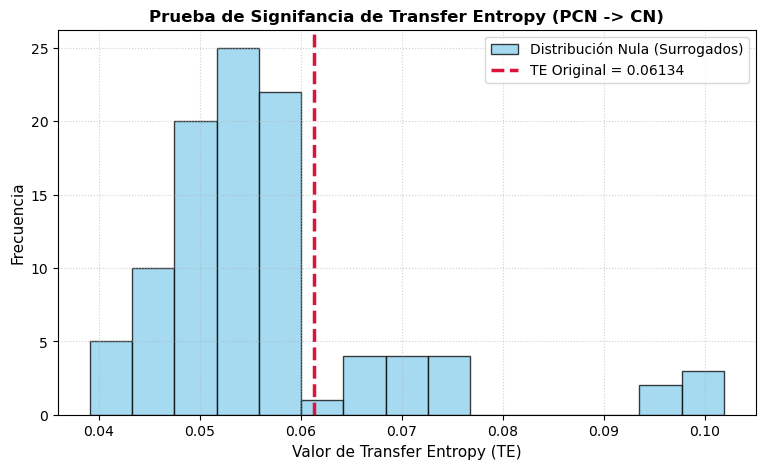

In [74]:
tau=13

PCN = scallops["PCN"].to_numpy()
CN = scallops["CN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(PCN.astype(np.float64), CN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (PCN -> CN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    PCN_surrogate = circular_surrogate(PCN)

    teCalc.initialise()
    teCalc.setObservations(PCN_surrogate.astype(np.float64), CN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (PCN -> CN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (CN -> PCN): 0.11217618716129762


Calculando surrogados: 100%|██████████| 100/100 [06:30<00:00,  3.91s/it]


Distribución nula - Media: 0.07376, Std: 0.01674
Pseudo p-valor: 0.0594059405940594


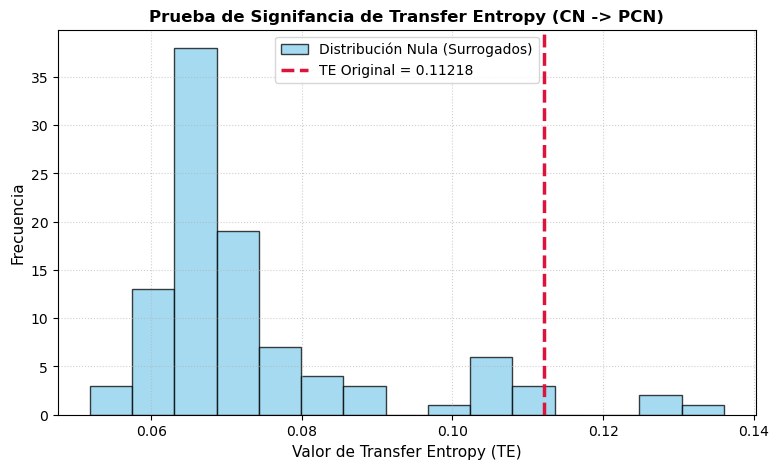

In [75]:
tau=2

CN = scallops["CN"].to_numpy()
PCN = scallops["PCN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(CN.astype(np.float64), PCN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (CN -> PCN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    CN_surrogate = circular_surrogate(CN)

    teCalc.initialise()
    teCalc.setObservations(CN_surrogate.astype(np.float64), PCN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (CN -> PCN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (DP -> PCN): -0.004821918863744612


Calculando surrogados: 100%|██████████| 100/100 [34:36<00:00, 20.76s/it]


Distribución nula - Media: -0.00172, Std: 0.01200
Pseudo p-valor: 0.49504950495049505


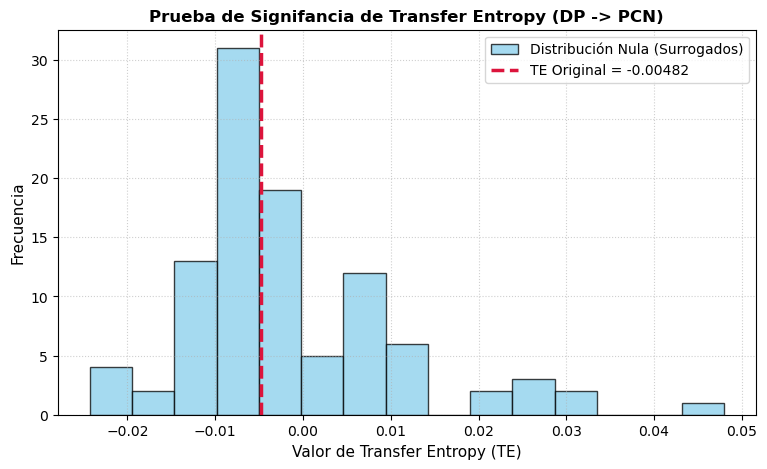

In [129]:
tau=75

DP = scallops["DP"].to_numpy()
PCN = scallops["PCN"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(DP.astype(np.float64), PCN.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (DP -> PCN): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    DP_surrogate = circular_surrogate(DP)

    teCalc.initialise()
    teCalc.setObservations(DP_surrogate.astype(np.float64), PCN.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (DP -> PCN)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

TE Original (PCN -> DP): 0.038861078129767135


Calculando surrogados: 100%|██████████| 100/100 [1:57:50<00:00, 70.71s/it]


Distribución nula - Media: 0.02091, Std: 0.00812
Pseudo p-valor: 0.10891089108910891


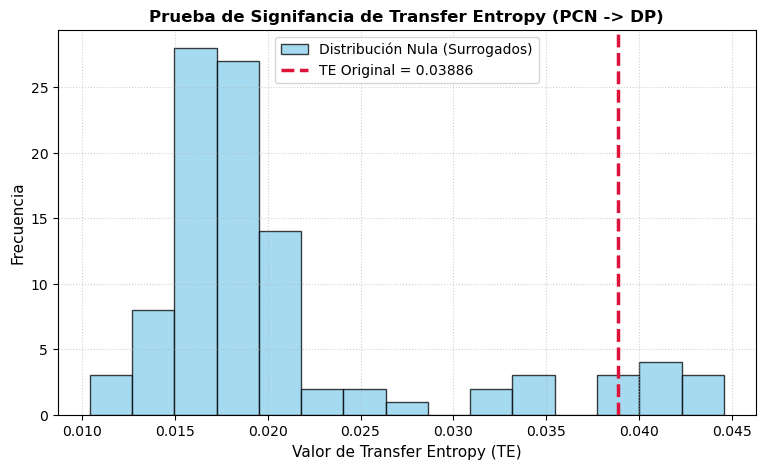

In [130]:
tau=350

PCN = scallops["PCN"].to_numpy()
DP = scallops["DP"].to_numpy()

teCalc = TECalcClass()
teCalc.setProperty("k", str(4))
teCalc.setProperty("k_HISTORY", str(1))
teCalc.setProperty("l_HISTORY", str(1))
teCalc.setProperty("DELAY", str(tau))
teCalc.initialise()

teCalc.setObservations(PCN.astype(np.float64), DP.astype(np.float64))
te_original = teCalc.computeAverageLocalOfObservations()
print(f"TE Original (PCN -> DP): {te_original}")

n_surrogates = 100
te_surrogates = np.zeros(n_surrogates)

for i in tqdm(range(n_surrogates), desc="Calculando surrogados"):
    PCN_surrogate = circular_surrogate(PCN)

    teCalc.initialise()
    teCalc.setObservations(PCN_surrogate.astype(np.float64), DP.astype(np.float64))
    te_surrogates[i] = teCalc.computeAverageLocalOfObservations()

p_value = (np.sum(te_surrogates >= te_original)+1) / (n_surrogates +1)
print(f"Distribución nula - Media: {np.mean(te_surrogates):.5f}, Std: {np.std(te_surrogates):.5f}")
print(f"Pseudo p-valor: {p_value}")

plt.figure(figsize=(9, 5))

count, bins, ignored = plt.hist(
    te_surrogates, 
    bins=15, 
    color='skyblue', 
    edgecolor='black', 
    alpha=0.75, 
    label='Distribución Nula (Surrogados)'
)

plt.axvline(
    te_original, 
    color='crimson', 
    linestyle='--', 
    linewidth=2.5, 
    label=f'TE Original = {te_original:.5f}'
)

plt.title('Prueba de Signifancia de Transfer Entropy (PCN -> DP)', fontsize=12, fontweight='bold')
plt.xlabel('Valor de Transfer Entropy (TE)', fontsize=11)
plt.ylabel('Frecuencia', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

---